# Vulnerabilidad de la red de carga aérea de Estados Unidos ante fallos simultáneos de aeropuertos · 2025

*Network Science for Data Analysis · Desarrollo del proyecto*

El notebook sigue el orden de un proyecto de datos: primero el problema y los
datos, después la red y las medidas, luego los resultados y, al final, la firmeza
de esos resultados. Cada bloque de código va precedido de lo que calcula y seguido
de su interpretación. Las funciones del análisis viven en los módulos `.py` de esta
carpeta; aquí se importan y se muestra el código de las piezas centrales (las tres
medidas, la simulación y el índice).

**Explorador interactivo (Atlas Cargo):** [`Atlas_Carga_Aerea_2025.html`](Atlas_Carga_Aerea_2025.html),
en la misma carpeta que este notebook. Es un único archivo HTML con los datos, el
mapa y el código incrustados: se abre con doble clic en cualquier navegador, sin
servidor ni conexión a internet. Sus cifras provienen de las tablas que este
notebook exporta en la sección 10.

## **0. Integrantes**

| Integrante | Número de identificación |
|---|---|
| \*\*\*\*\*\*\*\* | \*\*\*\*\*\*\*\*\*\* |
| \*\*\*\*\*\*\*\* | \*\*\*\*\*\*\*\*\*\* |

## **1. Marco del proyecto**

### **1.1. Trasfondo del negocio**

La carga aérea doméstica de Estados Unidos mueve cada mes decenas de miles de
millones de libras entre cientos de aeropuertos. A diferencia del transporte de
pasajeros, está muy concentrada: unas pocas compañías integradoras operan redes
*hub-and-spoke* en las que casi todo pasa por uno o dos centros de clasificación.
UPS concentra su operación en Louisville (SDF, Worldport), FedEx en Memphis
(MEM), y la red de Amazon Air se apoya en Cincinnati (CVG) y aeropuertos
secundarios como Rockford (RFD) o San Bernardino (SBD). Los grandes aeropuertos de
pasajeros (ORD, DFW, ATL, LAX) también mueven carga en bodega, y Anchorage (ANC)
es la puerta de entrada de la carga internacional que después se redistribuye.

Esa concentración es eficiente mientras todo funciona, y frágil cuando algo
falla: una tormenta, un cierre de pista, una caída de sistemas o una huelga
pueden sacar un aeropuerto del mapa durante horas o días. La pregunta de negocio
no es solo *qué aeropuerto es más importante*, sino **qué parejas de aeropuertos
no deberían fallar al mismo tiempo**, porque su fallo conjunto deja a la red sin
las alternativas que cada uno cubría del otro. Esa información sirve para
priorizar inversiones en redundancia, planes de contingencia y acuerdos de
desvío.

### **1.2. Artículo de referencia y pregunta de investigación**

Zhou, H., & Razavi, S. (2026). *An explanatory composite metric for air cargo
network robustness: incorporating pairwise synergistic effects*. *Scientific
Reports, 16*, 7071. https://doi.org/10.1038/s41598-026-38153-y

El artículo propone medir, para cada pareja de aeropuertos, la **sinergia**: cuánto
daña a la red retirar los dos a la vez, más allá de la suma de retirar cada uno por
separado. Combina tres medidas de robustez en un índice compuesto, lo calcula para
las 4.950 parejas de los 100 aeropuertos con más carga de 2022 y explica el índice
con una regresión para datos de red (MRQAP).

**Pregunta de este proyecto:** ¿qué parejas de aeropuertos producen un efecto
adicional sobre la robustez de la red doméstica de carga de 2025 al fallar juntas,
y qué tan firme es esa prioridad frente a las decisiones de construcción de la red
y al paso de los trimestres?

### **1.3. Objetivos y alcance**

**Objetivo general.** Adaptar la metodología del artículo a los datos de 2025 y
aportar un análisis de la firmeza de sus resultados.

**Objetivos específicos.**

1. Construir, con trazabilidad completa, la red de carga aérea doméstica de 2025
   (anual y por trimestres) sobre los 100 aeropuertos de mayor carga.
2. Explorar la estructura de esa red antes de perturbarla: medidas globales y
   locales, centralidades, tipo de red, comunidades y asortatividad.
3. Calcular las tres medidas de robustez, simular todos los fallos individuales y
   dobles, y construir el índice compuesto de sinergia.
4. Explicar el índice con MRQAP y evaluar su firmeza frente a trimestres,
   definiciones de enlace, caminos entre supervivientes y operadores.
5. Entregar un explorador interactivo que use exactamente estos resultados.

**Qué se mide y qué no.** El índice describe **vulnerabilidad estructural** de una
red binaria: existencia de conexiones y caminos. No estima toneladas perdidas,
costes, probabilidades de fallo, capacidad de desvío ni acuerdos entre compañías.
Los resultados son para 2025 y no se presentan como una réplica numérica del
estudio de 2022.

### **1.4. Plan de trabajo**

| Fase | Sección | Qué se hace | Producto |
|---|---|---|---|
| Entendimiento de los datos | 2 | Fuentes, estructura, calidad y exploración del archivo BTS T-100 | Diccionario, diagnóstico de calidad |
| Preparación | 3 | Reglas de limpieza, selección de 100 aeropuertos, coordenadas, agregación | Tablas depuradas y catálogo |
| Modelamiento y exploración de la red | 4 | De la tabla a cinco grafos binarios; centralidades, tipo de red, comunidades, asortatividad | Redes, mapa, perfil estructural |
| Medidas de robustez | 5 | Definición y fórmulas de eficiencia global, local y conectividad natural; validación | Funciones verificadas |
| Simulación de fallos | 6 | 100 fallos individuales y 4.950 dobles en cada una de las cinco redes (anual y cuatro trimestres) | Cachés de simulación |
| Índice compuesto | 7 | Normalización, pesos por entropía, ranking; sinergia frente a daño | Ranking anual |
| Explicación | 8 | Distancia, centralidades y conexión directa como predictores (MRQAP, M1–M5) y la sensibilidad M6 del artículo | Modelos |
| Firmeza de los resultados | 9 | Trimestres, reglas de enlace, parejas persistentes, caminos, operadores, valores p con otro método | Sensibilidades |
| Exportación | 10 | Tablas, figuras y JSON del explorador | App Atlas Cargo |
| Conclusiones | 11 | Hallazgos, comparación con el artículo, límites | Discusión |

## **2. Entendimiento de los datos**

### **2.1. Fuentes de datos**

La fuente principal es la tabla **T-100 Domestic Segment (All Carriers)** del Bureau
of Transportation Statistics (BTS), año 2025, doce meses. Es el reporte obligatorio
de cada transportista estadounidense para cada segmento operado (un despegue y un
aterrizaje), agregado por mes. Es pública, oficial y la misma familia de datos que
usa el artículo.

El análisis parte de tres archivos locales guardados en `data/raw/`; no descarga
nada durante la ejecución:

| Archivo (`data/raw/`) | Qué aporta | Dónde se usa |
|---|---|---|
| `BTS_T100_Domestic_Segment_All_Carriers_2025.zip` | Segmentos mensuales: carga, correo, salidas, distancia, transportista y clase de servicio | Toda la red y el análisis |
| `coordenadas_bts.csv` (BTS *Master Coordinate*) | Latitud, longitud y nombre oficial de cada versión de aeropuerto | Mapas (4.1 y 4.2), distancia geográfica de la regresión (8.1) y app. No interviene en la red ni en las medidas |
| `ne_110m_admin_0_countries.geojson` (Natural Earth) | Contorno de los países | Solo el fondo de los mapas estáticos |

El ZIP se obtuvo el 4 de octubre de 2026 en el
[formulario T-100 de TranStats](https://transtats.bts.gov/DL_SelectFields.aspx?gnoyr_VQ=GEE&QO_fu146_anzr=Nv4+Pn44vr45),
seleccionando 2025, *All Months* y todos los campos. El
[diccionario de variables](https://transtats.bts.gov/Fields.asp?gnoyr_VQ=GEE) y el
[catálogo de coordenadas](https://transtats.bts.gov/Fields.asp?gnoyr_VQ=FLL) documentan
las columnas. El script `src/adquirir_bts.py` conserva el procedimiento de descarga para
quien quiera obtener una edición nueva; una revisión posterior de BTS cambiaría la
huella SHA-256 y, con ella, la edición del estudio.

La primera celda carga las bibliotecas y las funciones del proyecto; la segunda
fija los parámetros y comprueba que los tres archivos son exactamente los usados.

In [1]:
# Bibliotecas estándar
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata   # versiones de los paquetes (sección 10)
import inspect              # muestra el código de las funciones centrales
import platform             # versión de Python (sección 10)
import sys
import time                 # duración de la simulación (sección 6)

# Cálculo y gráficos
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns       # mapas de calor de la sección 9.1
from IPython.display import display, Markdown, Code

# Módulos del proyecto (carpeta desarrollo/)
candidate = Path.cwd().resolve()
ROOT = candidate/'desarrollo' if (candidate/'desarrollo'/'analisis_red.py').exists() else candidate
SRC = ROOT/'src' if (ROOT/'src'/'analisis_red.py').exists() else ROOT   # en el repositorio el código está en src/
sys.path.insert(0, str(SRC))
from analisis_red import (METRICS, PERIODS, ALGORITHM_VERSION, sha256_file, write_json,
                          read_t100, clean_t100, airport_catalog, aggregate_routes, build_networks,
                          _efficiencies, robustness_metrics, verify_metrics, simulate_period,
                          entropy_composite, attach_results, compare_quarters, haversine_km,
                          pair_predictors, mrqap_models, export_app)
from coordenadas import merge_coordinates
from exploracion_red import (explore_base_networks, explore_variant_networks, export_exploration,
                             model_table, top_by_centrality)
from graficos_exploracion import plot_degree_and_models, plot_community_map
from ejecutar_ampliaciones import run_project_extensions
from ampliaciones_estructura import VARIANTS
from exportar_explorador import export_explorer, VARIANT_ORDER
from graficos_estabilidad import plot_stability_ranges
from graficos_ampliaciones import plot_extensions
from inferencia_ampliada import _designs, _fit


def show_code(*functions):
    """Muestra el código fuente de funciones del proyecto (también las compiladas con numba)."""
    source = '\n\n'.join(inspect.getsource(getattr(f, 'py_func', f)) for f in functions)
    display(Code(source, language='python'))


print('Bibliotecas y módulos cargados. Python', sys.version.split()[0])

Bibliotecas y módulos cargados. Python 3.14.0


In [2]:
YEAR, TOP_N, SEED = 2025, 100, 2025
USAR_CACHE = True          # False recalcula la simulación de fallos desde cero
EJECUTAR_MRQAP = True
N_PERMUTACIONES = 9999

RAW_DIR, OUT, FIG, CACHE = [ROOT/x for x in ['data/raw', 'resultados', 'figuras', 'cache']]
for directory in [OUT, FIG, CACHE]:
    directory.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 18)
pd.set_option('display.float_format', lambda x: f'{x:,.5f}')
sns.set_theme(style='whitegrid', palette=['#087f8c', '#dd9c36', '#426b9a', '#b55a52'])
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'axes.titleweight': 'bold'})


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG/name, bbox_inches='tight')
    plt.show()


# Archivos de entrada y su huella SHA-256 (edición usada en esta entrega)
SOURCES = {
    'T-100 Domestic Segment 2025': (RAW_DIR/'BTS_T100_Domestic_Segment_All_Carriers_2025.zip',
                                    'f2e386f1aa92636fa43bc7d9c8f0904077aeb162503d30f45b696d63afb26fac'),
    'BTS Master Coordinate': (RAW_DIR/'coordenadas_bts.csv',
                              '84c4e9269567665823954737d4925663af57fd6249f47f456bff3d28ed0aec8b'),
    'Natural Earth, países 1:110m': (RAW_DIR/'ne_110m_admin_0_countries.geojson',
                                     '8fce3a3e7c232cf9ae727273e7081dcc016f1f31dc13549ad028a70cb7905690'),
}
rows = []
for name, (path, expected) in SOURCES.items():
    if not path.exists():
        raise FileNotFoundError(f'Falta {path.name} en data/raw/; adquirir_bts.py documenta cómo obtenerlo.')
    digest = sha256_file(path)
    rows.append({'fuente': name, 'archivo': path.name, 'tamaño (MB)': path.stat().st_size/1e6,
                 'SHA-256': digest[:16] + '…', 'coincide con la edición del estudio': digest == expected})
display(pd.DataFrame(rows))
ZIP_PATH, COORD_CSV, WORLD_GEOJSON = (path for path, _ in SOURCES.values())
source_hash = sha256_file(ZIP_PATH)
SAME_EDITION = source_hash == SOURCES['T-100 Domestic Segment 2025'][1]
if not SAME_EDITION:
    print('Atención: el ZIP no es la edición del 4 de octubre de 2026; los resultados pueden diferir.')

,fuente,archivo,tamaño (MB),SHA-256,coincide con la edición del estudio
0,T-100 Domestic Segment 2025,BTS_T100_Domestic_Segment_All_Carriers_2025.zip,14.53856,f2e386f1aa92636f…,True
1,BTS Master Coordinate,coordenadas_bts.csv,4.55195,84c4e92695676658…,True
2,"Natural Earth, países 1:110m",ne_110m_admin_0_countries.geojson,0.98338,8fce3a3e7c232cf9…,True


### **2.2. Cómo vienen los datos**

Antes de limpiar conviene entender qué es una fila. En T-100 **una fila es un
agregado mensual de un segmento (origen → destino) operado por un transportista
con una configuración de aeronave y una clase de servicio**. Por eso la misma ruta
puede aparecer varias veces en el mismo mes: una fila por compañía, por tipo de
avión o por clase. Esas filas no son duplicados; son operaciones distintas que
luego se suman.

La celda abre el archivo tal como llega, muestra sus primeras filas, el
diccionario de las columnas usadas, su resumen numérico y la carga por clase de
servicio.

In [3]:
raw = read_t100(ZIP_PATH)
print(f'Filas: {len(raw):,} · columnas: {raw.shape[1]} · memoria: {raw.memory_usage(deep=True).sum()/1e6:,.0f} MB')
display(raw.head(5))
dictionary = pd.DataFrame([
    ('YEAR · MONTH · QUARTER', 'Calendario del registro', 'Define el período: año completo y cuatro trimestres'),
    ('ORIGIN_AIRPORT_ID · DEST_AIRPORT_ID', 'Identificadores BTS estables de origen y destino (AirportID)', 'Nodos de la red'),
    ('ORIGIN · DEST', 'Códigos de aeropuerto (IATA)', 'Etiquetas legibles'),
    ('ORIGIN_CITY_NAME · DEST_CITY_NAME · *_STATE_ABR', 'Ciudad y estado', 'Descripción y mapa'),
    ('ORIGIN_CITY_MARKET_ID · DEST_CITY_MARKET_ID', 'Mercado urbano: área metropolitana a la que BTS asigna el aeropuerto', 'Contexto (11.4)'),
    ('UNIQUE_CARRIER_NAME · AIRLINE_ID', 'Transportista que reporta', 'Capas por operador'),
    ('FREIGHT', 'Carga transportada en el segmento, en libras', 'Criterio de enlace y volumen bilateral'),
    ('MAIL', 'Correo, en libras', 'Se conserva aparte; no se suma a FREIGHT'),
    ('DISTANCE', 'Distancia del segmento, en millas', 'Auditoría; no define caminos en la red binaria'),
    ('DEPARTURES_PERFORMED', 'Salidas realizadas', 'Descripción de rutas'),
    ('CLASS', 'Clase de servicio: F regular pasajeros y carga · G regular solo carga · L chárter pasajeros y carga · P chárter solo carga',
     'No se filtra; documenta heterogeneidad'),
], columns=['columna', 'significado', 'uso en este proyecto'])
display(dictionary)
numeric_columns = ['FREIGHT', 'MAIL', 'PASSENGERS', 'DISTANCE', 'DEPARTURES_PERFORMED']
display(raw[numeric_columns].describe(percentiles=[.5, .9, .99]).T)
rows_per_route_month = raw.groupby(['MONTH', 'ORIGIN_AIRPORT_ID', 'DEST_AIRPORT_ID']).size()
print(f'Combinaciones mes × ruta: {len(rows_per_route_month):,}; filas por combinación: '
      f'mediana {rows_per_route_month.median():.0f}, máximo {rows_per_route_month.max()}.')
CLASS_NAMES = {'F': 'Regular de pasajeros y carga (carga en bodega)', 'G': 'Regular solo de carga',
               'L': 'No regular (chárter) de pasajeros y carga', 'P': 'No regular (chárter) solo de carga'}
classes = raw.groupby('CLASS').agg(filas=('FREIGHT', 'size'), carga_lb=('FREIGHT', 'sum'))
classes.insert(0, 'significado', classes.index.map(CLASS_NAMES))
classes['cuota de la carga'] = classes.carga_lb/classes.carga_lb.sum()
display(classes)

Filas: 458,793 · columnas: 45 · memoria: 497 MB


,DEPARTURES_SCHEDULED,DEPARTURES_PERFORMED,PAYLOAD,SEATS,PASSENGERS,FREIGHT,MAIL,DISTANCE,RAMP_TO_RAMP,...,DEST_WAC,AIRCRAFT_GROUP,AIRCRAFT_TYPE,AIRCRAFT_CONFIG,YEAR,QUARTER,MONTH,DISTANCE_GROUP,CLASS
0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,...,1,1,194,1,2025,1,3,1,F
1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,...,33,6,724,1,2025,1,2,1,F
2,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,...,91,6,724,1,2025,1,2,1,F
3,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,17.00000,0.00000,...,3,1,131,1,2025,3,8,1,F
4,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,17.00000,0.00000,...,3,1,131,1,2025,3,8,1,F


,columna,significado,uso en este proyecto
0,YEAR · MONTH · QUARTER,Calendario del registro,Define el período: año completo y cuatro trime...
1,ORIGIN_AIRPORT_ID · DEST_AIRPORT_ID,Identificadores BTS estables de origen y desti...,Nodos de la red
2,ORIGIN · DEST,Códigos de aeropuerto (IATA),Etiquetas legibles
3,ORIGIN_CITY_NAME · DEST_CITY_NAME · *_STATE_ABR,Ciudad y estado,Descripción y mapa
4,ORIGIN_CITY_MARKET_ID · DEST_CITY_MARKET_ID,Mercado urbano: área metropolitana a la que BT...,Contexto (11.4)
5,UNIQUE_CARRIER_NAME · AIRLINE_ID,Transportista que reporta,Capas por operador
6,FREIGHT,"Carga transportada en el segmento, en libras",Criterio de enlace y volumen bilateral
7,MAIL,"Correo, en libras",Se conserva aparte; no se suma a FREIGHT
8,DISTANCE,"Distancia del segmento, en millas",Auditoría; no define caminos en la red binaria
9,DEPARTURES_PERFORMED,Salidas realizadas,Descripción de rutas


,count,mean,std,min,50%,90%,99%,max
FREIGHT,"458,793.00000","56,558.65287","437,171.02571",0.00000,0.00000,"14,105.00000","1,600,106.36000","43,475,435.00000"
MAIL,"458,793.00000","4,993.70311","59,299.83639",0.00000,0.00000,0.00000,"89,329.28000","3,512,758.00000"
PASSENGERS,"458,793.00000","1,849.57797","3,586.65097",0.00000,408.00000,"5,066.00000","16,891.24000","74,491.00000"
DISTANCE,"458,793.00000",763.61372,633.26485,0.00000,628.00000,"1,619.00000","2,688.00000","7,657.00000"
DEPARTURES_PERFORMED,"458,793.00000",19.69624,32.72670,0.00000,7.00000,54.00000,146.00000,"1,036.00000"


Combinaciones mes × ruta: 151,221; filas por combinación: mediana 2, máximo 43.


,significado,filas,carga_lb,cuota de la carga
CLASS,,,,
F,Regular de pasajeros y carga (carga en bodega),359158,"1,213,223,120.00000",0.04675
G,Regular solo de carga,34915,"18,833,410,233.00000",0.72579
L,No regular (chárter) de pasajeros y carga,55001,"96,001,081.00000",0.00370
P,No regular (chárter) solo de carga,9719,"5,806,079,590.00000",0.22375


**Interpretación.** El archivo trae 45 columnas y cerca de 459 mil filas. `FREIGHT`
tiene una mediana de cero y un percentil 99 muy alto: la mayoría de las filas son
vuelos de pasajeros sin mercancía y unas pocas rutas concentran la carga. Una misma
ruta y mes aparece en varias filas (varios transportistas o clases), lo que confirma
que habrá que **agregar** antes de construir la red. Las clases G y P, aviones
cargueros regulares y chárter, transportan cerca del 95 % de la carga; la clase F
es la carga en bodega de los vuelos de pasajeros.

Antes de explorar, un inventario de **cuántas entidades distintas** contiene el
archivo: aeropuertos, transportistas, rutas y meses, en total y solo donde hubo
mercancía. Estas cifras definen el tamaño máximo posible de la red.

In [4]:
cargo_rows = raw[raw.FREIGHT > 0]


def inventory(frame):
    airports_seen = set(frame.ORIGIN_AIRPORT_ID) | set(frame.DEST_AIRPORT_ID)
    directed = frame[['ORIGIN_AIRPORT_ID', 'DEST_AIRPORT_ID']].drop_duplicates()
    undirected = pd.DataFrame({'u': np.minimum(frame.ORIGIN_AIRPORT_ID, frame.DEST_AIRPORT_ID),
                               'v': np.maximum(frame.ORIGIN_AIRPORT_ID, frame.DEST_AIRPORT_ID)})
    undirected = undirected[undirected.u != undirected.v].drop_duplicates()
    return {'filas': len(frame),
            'aeropuertos distintos (origen o destino)': len(airports_seen),
            'estados o territorios': frame[['ORIGIN_STATE_ABR', 'DEST_STATE_ABR']].stack().nunique(),
            'transportistas (AIRLINE_ID)': frame.AIRLINE_ID.nunique(),
            'rutas dirigidas origen → destino': len(directed),
            'parejas de aeropuertos sin dirección': len(undirected),
            'meses': frame.MONTH.nunique(),
            'tipos de aeronave': frame.AIRCRAFT_TYPE.nunique(),
            'carga total (millones de lb)': round(frame.FREIGHT.sum()/1e6, 1)}


inventory_table = pd.DataFrame({'archivo completo': inventory(raw), 'solo filas con mercancía': inventory(cargo_rows)})
display(inventory_table.map(lambda v: f'{v:,.1f}' if isinstance(v, float) and not float(v).is_integer() else f'{int(v):,}'))

,archivo completo,solo filas con mercancía
filas,"458,793","192,290"
aeropuertos distintos (origen o destino),"1,349",775
estados o territorios,53,53
transportistas (AIRLINE_ID),190,105
rutas dirigidas origen → destino,"31,224","10,170"
parejas de aeropuertos sin dirección,"19,340","6,322"
meses,12,12
tipos de aeronave,148,92
carga total (millones de lb),"25,948.7","25,948.7"


**Interpretación.** El archivo describe 1.349 aeropuertos, 190 transportistas y más
de 31 mil rutas dirigidas, pero la mercancía circula por 775 aeropuertos, 105
transportistas y 6.322 parejas de aeropuertos. Esa es la red "completa" de carga:
varios cientos de nodos, la mayoría con muy poca carga. La sección 3.2 explica por
qué el análisis se concentra en los 100 mayores.

### **2.3. Calidad de los datos**

La revisión busca filas que no representan una conexión de carga o que no
corresponden al alcance del estudio, antes de aplicar ninguna regla.

In [5]:
quality = pd.Series({
    'años distintos de 2025': int((raw.YEAR != YEAR).sum()),
    'meses fuera de 1–12': int((~raw.MONTH.between(1, 12)).sum()),
    'trimestre incoherente con el mes': int((raw.QUARTER != ((raw.MONTH-1)//3+1)).sum()),
    'filas duplicadas exactas': int(raw.duplicated().sum()),
    'identificador de aeropuerto faltante': int(raw[['ORIGIN_AIRPORT_ID', 'DEST_AIRPORT_ID']].isna().any(axis=1).sum()),
    'FREIGHT faltante o no finito': int((~np.isfinite(raw.FREIGHT.astype(float))).sum()),
    'FREIGHT = 0 (sin mercancía)': int((raw.FREIGHT == 0).sum()),
    'FREIGHT < 0': int((raw.FREIGHT < 0).sum()),
    'origen igual al destino': int((raw.ORIGIN_AIRPORT_ID == raw.DEST_AIRPORT_ID).sum()),
    'DISTANCE faltante o ≤ 0': int((raw.DISTANCE.isna() | (raw.DISTANCE <= 0)).sum()),
    'MAIL > 0 con FREIGHT = 0': int(((raw.MAIL > 0) & (raw.FREIGHT == 0)).sum()),
}, name='filas')
display(quality.to_frame())
print(f'Filas sin mercancía: {(raw.FREIGHT == 0).mean():.1%} del archivo.')
print(f'Filas con origen igual al destino y carga positiva: {((raw.ORIGIN_AIRPORT_ID == raw.DEST_AIRPORT_ID) & (raw.FREIGHT > 0)).sum():,}.')

,filas
años distintos de 2025,0
meses fuera de 1–12,0
trimestre incoherente con el mes,0
filas duplicadas exactas,0
identificador de aeropuerto faltante,0
FREIGHT faltante o no finito,0
FREIGHT = 0 (sin mercancía),266503
FREIGHT < 0,0
origen igual al destino,4434
DISTANCE faltante o ≤ 0,4435


Filas sin mercancía: 58.1% del archivo.
Filas con origen igual al destino y carga positiva: 445.


**Interpretación.** No hay años ajenos a 2025, ni meses inválidos, ni duplicados
exactos, ni identificadores faltantes. Los dos hallazgos relevantes son: (1) más de
la mitad de las filas no transportan mercancía, por lo que no definen conexiones de
carga; (2) existen segmentos con **origen igual al destino** (vuelos que regresan al
mismo aeropuerto o reportes de posicionamiento) que no pueden ser enlaces de un
grafo sin bucles. Las filas con `MAIL > 0` y `FREIGHT = 0` muestran que el correo es
un flujo distinto: incluirlo cambiaría el alcance del estudio, así que se conserva
aparte.

### **2.4. Exploración inicial**

Tres preguntas antes de construir nada: ¿cómo se reparte la carga entre
transportistas?, ¿qué tan concentrada está por aeropuerto? y ¿cuánto varía por
mes? La concentración por aeropuerto es la base para trabajar con los 100 mayores,
como hace el artículo.

,carga_lb,cuota,cuota_acumulada
UNIQUE_CARRIER_NAME,,,
Federal Express Corporation,"7,944,218,492.00000",0.30615,0.30615
United Parcel Service,"6,997,559,963.00000",0.26967,0.57582
Air Transport International,"2,282,939,396.00000",0.08798,0.66380
Atlas Air Inc.,"1,422,459,694.00000",0.05482,0.71862
ABX Air Inc,"1,223,563,576.00000",0.04715,0.76577
Kalitta Air LLC,"745,841,124.00000",0.02874,0.79451
Hawaiian Airlines Inc.,"486,737,220.00000",0.01876,0.81327
Korean Air Lines Co. Ltd.,"475,557,477.00000",0.01833,0.83160
Cathay Pacific Airways Ltd.,"471,867,751.00000",0.01818,0.84978


190 transportistas reportan carga; los diez primeros suman 86.6%.


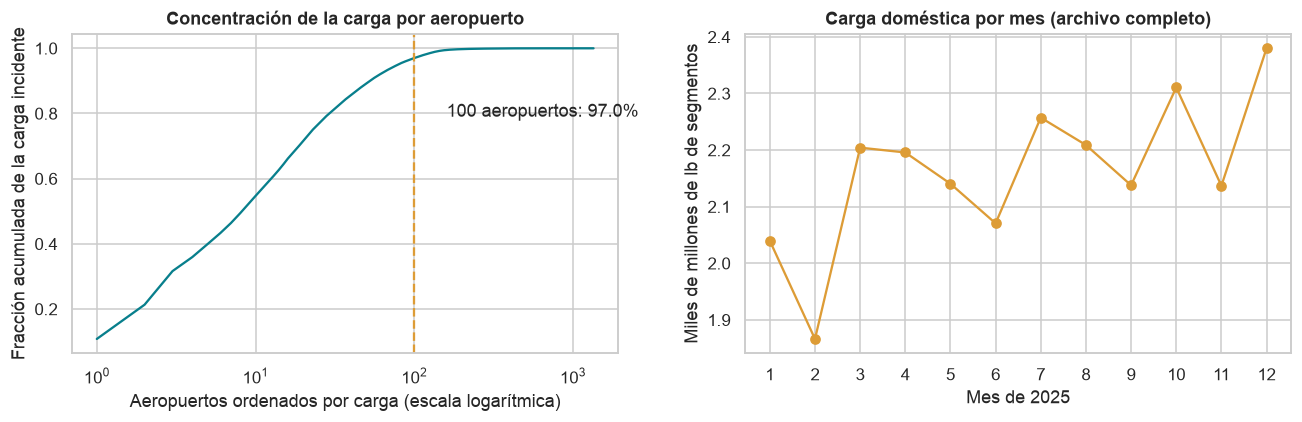

Aeropuertos con alguna carga: 775 de 1,349 identificadores.


In [6]:
carriers = raw.groupby('UNIQUE_CARRIER_NAME').FREIGHT.sum().sort_values(ascending=False)
carrier_share = carriers/carriers.sum()
display(pd.DataFrame({'carga_lb': carriers.head(10), 'cuota': carrier_share.head(10),
                      'cuota_acumulada': carrier_share.cumsum().head(10)}))
print(f'{len(carriers)} transportistas reportan carga; los diez primeros suman {carrier_share.head(10).sum():.1%}.')
incident = pd.concat([raw.groupby('ORIGIN_AIRPORT_ID').FREIGHT.sum(),
                      raw.groupby('DEST_AIRPORT_ID').FREIGHT.sum()], axis=1).fillna(0).sum(axis=1)
incident = incident.sort_values(ascending=False)
cumulative = incident.cumsum()/incident.sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, len(cumulative)+1), cumulative.values, color='#087f8c')
axes[0].axvline(TOP_N, ls='--', color='#dd9c36')
axes[0].set(xscale='log', xlabel='Aeropuertos ordenados por carga (escala logarítmica)',
            ylabel='Fracción acumulada de la carga incidente', title='Concentración de la carga por aeropuerto')
axes[0].annotate(f'{TOP_N} aeropuertos: {cumulative.iloc[TOP_N-1]:.1%}', (TOP_N, cumulative.iloc[TOP_N-1]),
                 xytext=(TOP_N*1.6, cumulative.iloc[TOP_N-1]-.18), arrowprops=dict(arrowstyle='->'))
monthly_raw = raw.groupby('MONTH').FREIGHT.sum()/1e9
axes[1].plot(monthly_raw.index, monthly_raw.values, marker='o', color='#dd9c36')
axes[1].set(title='Carga doméstica por mes (archivo completo)', xlabel='Mes de 2025',
            ylabel='Miles de millones de lb de segmentos', xticks=range(1, 13))
savefig('00_exploracion_inicial.png')
print(f'Aeropuertos con alguna carga: {int((incident > 0).sum()):,} de {len(incident):,} identificadores.')

**Interpretación.** Dos integradores (FedEx y UPS) reúnen más de la mitad de la
carga y diez compañías casi toda. La curva de concentración muestra que los 100
primeros aeropuertos acumulan más del 90 % de la carga incidente, con cientos de
aeropuertos pequeños que aportan muy poco. La carga mensual es relativamente
estable, con un aumento hacia fin de año (temporada de compras), lo que anticipa que
los trimestres pueden diferir en número de conexiones.

## **3. Preparación de los datos**

### **3.1. Reglas de limpieza**

Del diagnóstico anterior salen cinco reglas, aplicadas en este orden. Cada una
registra cuántas filas retira; ninguna elimina una ruta "por repetirse", porque
dos filas de la misma ruta pueden ser operaciones distintas.

| Regla | Por qué | Efecto esperado |
|---|---|---|
| Eliminar duplicados exactos | Una fila repetida íntegramente sería un error de carga | Ninguno en esta instantánea |
| Identificadores, códigos y calendario válidos; año 2025 y doce meses | Alcance del estudio | Ninguno en esta instantánea |
| Carga finita y estrictamente positiva | Sin mercancía no hay conexión de carga | Retira más de la mitad de las filas |
| Origen distinto del destino | Un grafo de aeropuertos no admite bucles | Retira unos cientos de filas |
| `MAIL` se conserva, pero no se suma | Es otro flujo; sumarlo cambiaría el alcance | Columna disponible para extensiones |

Las distancias se auditan, pero no se usan para definir caminos: en la red binaria
la distancia entre dos aeropuertos es el número de escalas, no las millas.

,stage,remaining,removed
0,Registros originales,458793,0
1,Eliminar duplicados exactos,458793,0
2,"Identificadores, códigos y calendario válidos",458793,0
3,Carga finita y estrictamente positiva,192290,266503
4,Origen diferente del destino,191845,445


Años: [2025] | duplicados exactos: 0
Filas con distancia no positiva o ausente: 0


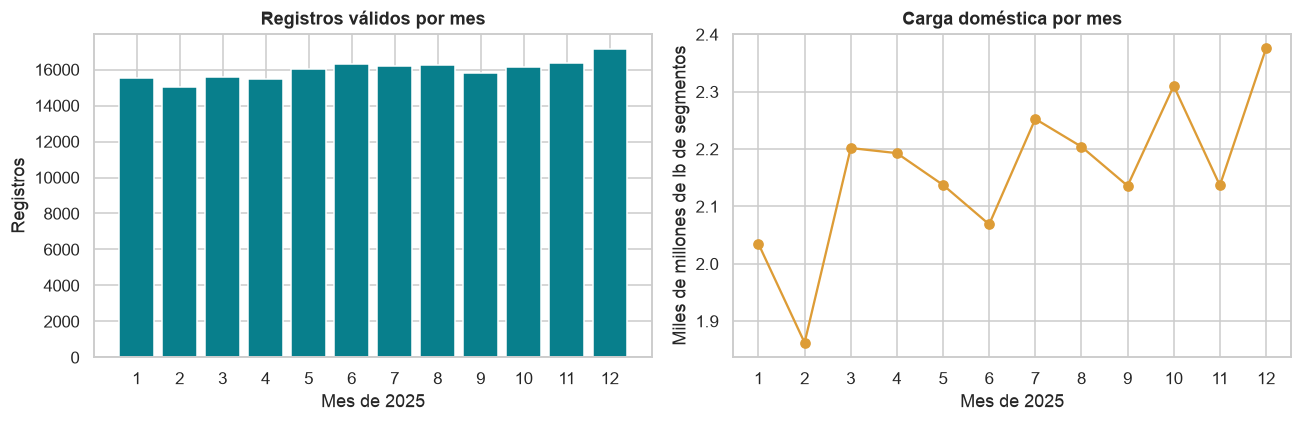

In [7]:
clean, audit = clean_t100(raw, YEAR)
audit.update(raw_zip_sha256=source_hash,
             original_download_date='2026-10-04' if SAME_EDITION else 'Edición distinta a la del estudio',
             analysis_timestamp_utc=datetime.now(timezone.utc).isoformat())
display(pd.DataFrame(audit['cleaning_steps']))
print('Años:', audit['source_years'], '| duplicados exactos:', audit['exact_duplicates'])
print('Filas con distancia no positiva o ausente:', audit['invalid_distance_rows'])
monthly = clean.groupby('MONTH').agg(registros=('FREIGHT', 'size'), freight_lb=('FREIGHT', 'sum')).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(monthly.MONTH, monthly.registros, color='#087f8c')
axes[0].set(title='Registros válidos por mes', xlabel='Mes de 2025', ylabel='Registros')
axes[1].plot(monthly.MONTH, monthly.freight_lb/1e9, marker='o', color='#dd9c36')
axes[1].set(title='Carga doméstica por mes', xlabel='Mes de 2025', ylabel='Miles de millones de lb de segmentos')
for ax in axes:
    ax.set_xticks(range(1, 13))
savefig('01_datos_mensuales.png')

**Interpretación.** De 458.793 filas quedan 191.845 con carga positiva entre
aeropuertos distintos. Las cifras coinciden con el diagnóstico de la sección 2.3: la
limpieza hizo exactamente lo previsto y nada más. Las filas depuradas se reparten de
forma pareja entre los doce meses.

### **3.2. Selección de los 100 aeropuertos: por qué 100**

El criterio es el del artículo: los 100 aeropuertos con mayor carga anual (entrante
más saliente), con desempate por identificador para que la selección sea
determinista. El número responde a cuatro razones:

1. **Comparabilidad con el artículo.** Zhou y Razavi usan los 100 aeropuertos con
   mayor carga de 2022 y reportan que cubren más del 92 % del total. Mantener el
   mismo tamaño permite comparar patrones (no cifras) entre 2022 y 2025.
2. **Cobertura.** Como muestra la tabla siguiente, con 100 aeropuertos se retiene
   la gran mayoría de la carga; pasar a 200 o 300 añade muy poco volumen y muchos
   nodos con una o dos conexiones esporádicas.
3. **Costo de la simulación.** El método evalúa las tres medidas para cada fallo
   individual y para cada pareja: con 100 nodos son 4.950 parejas por red; con 200
   serían 19.900 y con 300, 44.850, y cada evaluación incluye el espectro completo
   de la matriz de adyacencia. La implementación acelerada de la sección 5.3 admite
   hasta 128 nodos.
4. **Significado de la red.** Los aeropuertos pequeños aportan enlaces de muy bajo
   volumen que, en una red binaria, pesan igual que una ruta diaria; incluirlos
   añade ruido estructural más que información (la sección 9.2 muestra cuánto
   cambian los resultados al exigir persistencia incluso dentro de los 100).

**Dos formas de medir la cobertura.** Ambas responden cuánta carga queda dentro de
la red, pero tratan distinto un vuelo entre un aeropuerto seleccionado y uno
excluido. Ejemplo: un vuelo de 1.000 lb de MEM (dentro del top 100) a un aeropuerto
pequeño (fuera).

- **Cobertura por extremos (carga incidente).** Cada vuelo tiene dos extremos y
  cada extremo suma la carga del vuelo a su aeropuerto. Los 1.000 lb cuentan para
  MEM, que está seleccionado, y para el aeropuerto pequeño, que no: el vuelo aporta
  la mitad de su carga a esta cobertura. Mide qué tan grandes son los aeropuertos
  elegidos.
- **Cobertura interna (segmentos internos).** Solo cuenta un vuelo si sus dos
  extremos están en el top 100. El vuelo del ejemplo aporta cero, porque no puede
  ser un enlace de la red. Es la carga que viaja por los enlaces de la red y, por
  tanto, la que la red efectivamente representa.

El límite se declara: los aeropuertos excluidos podrían ofrecer alternativas de
desvío que la subred no ve.

In [8]:
coverage_rows = []
for n_top in [25, 50, 75, 100, 150, 200, 300, len(incident)]:
    chosen = set(incident.index[:n_top])
    inside = clean[clean.ORIGIN_AIRPORT_ID.isin(chosen) & clean.DEST_AIRPORT_ID.isin(chosen)]
    coverage_rows.append({'aeropuertos': n_top, 'parejas posibles': f'{n_top*(n_top-1)//2:,}',
                          'cobertura por extremos': f'{cumulative.iloc[n_top-1]:.1%}',
                          'cobertura interna': f'{inside.FREIGHT.sum()/clean.FREIGHT.sum():.1%}',
                          'carga del último seleccionado (lb)': f'{incident.iloc[n_top-1]:,.0f}'})
display(pd.DataFrame(coverage_rows).set_index('aeropuertos'))

airports, all_airports = airport_catalog(clean, TOP_N)
audit['selected_endpoint_freight_share'] = float(airports.annual_freight_lb.sum()/all_airports.annual_freight_lb.sum())
assert np.isclose(all_airports.annual_freight_lb.sum(), 2*clean.FREIGHT.sum())
code_to_id = dict(zip(airports.code, airports.airport_id))
display(airports[['annual_rank', 'code', 'airport_id', 'city', 'annual_freight_lb']].head(15)
        .rename(columns={'annual_rank': 'puesto', 'code': 'código IATA', 'airport_id': 'AirportID BTS',
                         'city': 'ciudad', 'annual_freight_lb': 'carga incidente (lb)'}))

,parejas posibles,cobertura por extremos,cobertura interna,carga del último seleccionado (lb)
aeropuertos,,,,
25,300,76.8%,57.8%,"441,781,521"
50,"1,225",89.2%,80.0%,"157,127,602"
75,"2,775",94.4%,89.7%,"72,396,390"
100,"4,950",97.0%,94.5%,"38,048,476"
150,"11,175",99.3%,98.8%,"10,688,789"
200,"19,900",99.8%,99.5%,"1,832,410"
300,"44,850",99.9%,99.9%,"428,907"
1349,"909,226",100.0%,100.0%,0


,puesto,código IATA,AirportID BTS,ciudad,carga incidente (lb)
0,1,ANC,10299,"Anchorage, AK","5,607,935,939.00000"
1,2,SDF,14730,"Louisville, KY","5,456,133,913.00000"
2,3,MEM,13244,"Memphis, TN","5,347,775,247.00000"
3,4,ORD,13930,"Chicago, IL","2,234,828,019.00000"
4,5,CVG,11193,"Cincinnati, OH","2,076,703,211.00000"
5,6,LAX,12892,"Los Angeles, CA","1,725,457,073.00000"
6,7,IND,12339,"Indianapolis, IN","1,597,644,631.00000"
7,8,MIA,13303,"Miami, FL","1,527,457,816.00000"
8,9,ONT,13891,"Ontario, CA","1,467,062,366.00000"
9,10,JFK,12478,"New York, NY","1,285,498,560.00000"


**Interpretación.** Con 100 aeropuertos la subred conserva el 94,5 % de la carga
como cobertura interna y el 97 % como cobertura por extremos. Pasar a 150 sube la
cobertura interna a 98,8 % con más del doble de parejas, y a 200 la lleva a 99,5 %
cuadruplicándolas. El aeropuerto número 100 todavía mueve 38 millones de libras al
año; el número 200, menos de dos millones. El corte en 100 es un equilibrio entre
cobertura y costo, además de la referencia del artículo. Anchorage, Louisville,
Memphis y Chicago O'Hare encabezan la lista.

### **3.3. Coordenadas**

Las coordenadas del catálogo *Master Coordinate* de BTS se unen por `AirportSeqID`,
la versión del aeropuerto observada en los registros de 2025; si hubo varias
versiones en el año, se toma la del último mes. Sirven para los mapas, para la
distancia geográfica de la regresión (8.1) y para la app; no intervienen en la red
ni en las medidas.

In [9]:
airports, geo_audit = merge_coordinates(airports, clean, pd.read_csv(COORD_CSV, low_memory=False))
airports.to_csv(OUT/'catalogo_aeropuertos.csv', index=False)   # lo leen las ampliaciones de la sección 9
display(pd.DataFrame([geo_audit]).drop(columns=['selection_rule', 'temporal_scope', 'dictionary_url']))

,selected_airports,matched_airports,observed_airport_seq_ids,matched_airport_seq_ids,airports_with_multiple_versions,airports_with_coordinate_changes,unmatched_sequences
0,100,100,144,144,44,43,[]


**Interpretación.** Los 100 aeropuertos encuentran coordenadas: se observaron 144
versiones de aeropuerto en 2025 y todas existen en el catálogo. 44 aeropuertos
tuvieron más de una versión en el año, y en 43 de ellos las coordenadas difieren
entre versiones; por eso se fija la versión del último mes.

### **3.4. Agregación: de filas a enlaces**

La agregación es **mensual y dirigida**, y la red de cada período resulta de sumar
esos meses. La cadena completa es esta:

1. **Filas depuradas:** una fila por mes, transportista, avión, clase y segmento.
2. **Rutas mensuales** (`routes`): suma por mes, origen y destino; una fila por
   ruta dirigida y mes, con su carga, correo, salidas y distancia mediana.
3. **Dentro del top 100:** solo las rutas con origen y destino entre los 100.
4. **Red de un período:** se filtran los meses del período (año o trimestre), se
   unen los dos sentidos A→B y B→A y se suma la carga: una fila por pareja.
5. **Red binaria:** el enlace existe si esa suma es positiva.

El nivel mensual se conserva por dos razones: permite construir los trimestres sin
volver a los datos crudos, y las reglas alternativas de la sección 9.2 necesitan
saber en cuántos meses aparece cada enlace. La celda calcula el tamaño de cada paso
y muestra un ejemplo.

In [10]:
routes = aggregate_routes(clean)
assert np.isclose(routes.freight_lb.sum(), clean.FREIGHT.sum())
selected_ids = set(airports.airport_id)
inside_routes = routes[routes.ORIGIN_AIRPORT_ID.isin(selected_ids) & routes.DEST_AIRPORT_ID.isin(selected_ids)]
pair_u = np.minimum(inside_routes.ORIGIN_AIRPORT_ID, inside_routes.DEST_AIRPORT_ID)
pair_v = np.maximum(inside_routes.ORIGIN_AIRPORT_ID, inside_routes.DEST_AIRPORT_ID)
display(pd.DataFrame({'filas': {
    '1. filas depuradas': len(clean),
    '2. rutas mensuales (mes × origen → destino)': len(routes),
    '3. rutas mensuales dentro del top 100': len(inside_routes),
    '4. parejas con carga en el año (enlaces anuales)': len(set(zip(pair_u, pair_v)))}}))


def monthly_link(a, b, quarter=None):
    """Carga y salidas mensuales del enlace a–b, sumando los dos sentidos."""
    ida, idb = code_to_id[a], code_to_id[b]
    link = routes[((routes.ORIGIN_AIRPORT_ID == ida) & (routes.DEST_AIRPORT_ID == idb)) |
                  ((routes.ORIGIN_AIRPORT_ID == idb) & (routes.DEST_AIRPORT_ID == ida))]
    if quarter is not None:
        link = link[link.QUARTER == quarter]
    return (link.groupby(['QUARTER', 'MONTH'], as_index=False)
                .agg(sentidos=('ORIGIN_AIRPORT_ID', 'nunique'), carga_lb=('freight_lb', 'sum'),
                     salidas=('departures', 'sum'))
                .rename(columns={'QUARTER': 'trimestre', 'MONTH': 'mes'}))


example = monthly_link('MEM', 'MCI')
print(f'Ejemplo MEM–MCI: {len(routes[routes.ORIGIN_AIRPORT_ID.isin([code_to_id["MEM"], code_to_id["MCI"]]) & routes.DEST_AIRPORT_ID.isin([code_to_id["MEM"], code_to_id["MCI"]])])} '
      f'rutas mensuales dirigidas forman un único enlace anual con {example.carga_lb.sum()/1e6:,.1f} millones de lb.')
display(example.head(6))

,filas
1. filas depuradas,191845
2. rutas mensuales (mes × origen → destino),68473
3. rutas mensuales dentro del top 100,36262
4. parejas con carga en el año (enlaces anuales),2441


Ejemplo MEM–MCI: 24 rutas mensuales dirigidas forman un único enlace anual con 41.8 millones de lb.


,trimestre,mes,sentidos,carga_lb,salidas
0,1,1,2,"2,893,493.00000",45.00000
1,1,2,2,"2,706,096.00000",37.00000
2,1,3,2,"3,204,877.00000",43.00000
3,2,4,2,"3,699,717.00000",50.00000
4,2,5,2,"3,942,312.00000",51.00000
5,2,6,2,"3,302,009.00000",45.00000


**Interpretación.** Las 191.845 filas depuradas se reducen a 68.473 rutas mensuales;
36.262 de ellas unen dos aeropuertos del top 100 y forman 2.441 enlaces anuales. En
el ejemplo, MEM–MCI aparece en las dos direcciones durante los doce meses (24 rutas
mensuales) y queda como un solo enlace anual.

## **4. Modelamiento como red y análisis exploratorio de la red**

### **4.1. Decisiones de modelamiento**

| Elemento | Decisión | Origen |
|---|---|---|
| Nodo | Cada uno de los 100 aeropuertos, identificado por su AirportID de BTS (y su código IATA como etiqueta) | Artículo |
| Enlace | Existe si hubo carga positiva en **cualquier** sentido durante el período; sin bucles | Artículo (red simetrizada) |
| Peso | El grafo es **binario** (1 si hay conexión, 0 si no); el volumen bilateral se guarda como atributo descriptivo | Decisión propia, coherente con las medidas |
| Dirección | No dirigido | Artículo: las tres medidas se definen para grafos no dirigidos |
| Períodos | Año completo y cuatro trimestres, siempre con los mismos 100 nodos | Aporte propio |
| Fallo | Retirar el aeropuerto y todas sus conexiones; sin redistribución de mercancía | Artículo |

Dos consecuencias que conviene tener presentes. Primera: una ruta con 16 libras en
un mes cuenta igual que una ruta diaria, porque el grafo solo registra existencia;
la sección 9.2 mide cuánto cambia el resultado si se exige persistencia o volumen.
Segunda: la red anual reúne enlaces observados en cualquier mes; no significa que
todos operen a la vez.

La tabla siguiente resume las cinco redes. Las tres últimas columnas son la
cobertura interna de cada período: carga de los segmentos con ambos extremos en el
top 100, carga de todos los segmentos depurados del período y su cociente.

In [11]:
networks = build_networks(routes, airports)
union = np.logical_or.reduce([networks[q]['adj'] for q in ['T1', 'T2', 'T3', 'T4']])
assert np.array_equal(union, networks['annual']['adj'])
assert np.isclose(sum(networks[q]['stats']['freight_lb'] for q in ['T1', 'T2', 'T3', 'T4']),
                  networks['annual']['stats']['freight_lb'])
assert all(list(n['graph'].nodes) == airports.airport_id.tolist() for n in networks.values())
summary = pd.DataFrame([{'period': p, **n['stats']} for p, n in networks.items()])
display(summary.rename(columns={
    'period': 'período', 'n_nodes': 'nodos', 'n_edges': 'enlaces', 'density': 'densidad',
    'components': 'componentes', 'largest_component': 'componente mayor', 'isolates': 'aislados',
    'freight_lb': 'carga interna (lb)', 'all_network_freight_lb': 'carga total del período (lb)',
    'inside_freight_share': 'cobertura interna'}))

,período,nodos,enlaces,densidad,componentes,componente mayor,aislados,carga interna (lb),carga total del período (lb),cobertura interna
0,annual,100,2441,0.49313,1,100,0,"24,489,600,379.00000","25,913,325,322.00000",0.94506
1,T1,100,1818,0.36727,1,100,0,"5,762,528,097.00000","6,099,113,572.00000",0.94481
2,T2,100,1879,0.37960,1,100,0,"6,041,535,478.00000","6,399,196,969.00000",0.94411
3,T3,100,1947,0.39333,1,100,0,"6,219,418,581.00000","6,592,673,867.00000",0.94338
4,T4,100,1994,0.40283,1,100,0,"6,466,118,223.00000","6,822,340,914.00000",0.94779


**Interpretación.** La red anual tiene 2.441 enlaces y los trimestres entre 1.818 y
1.994; la unión de los cuatro trimestres reproduce exactamente la anual (el código
lo comprueba). Todas son conexas y sin nodos aislados. La cobertura interna se
mantiene entre 94,3 % y 94,8 % en todos los períodos.

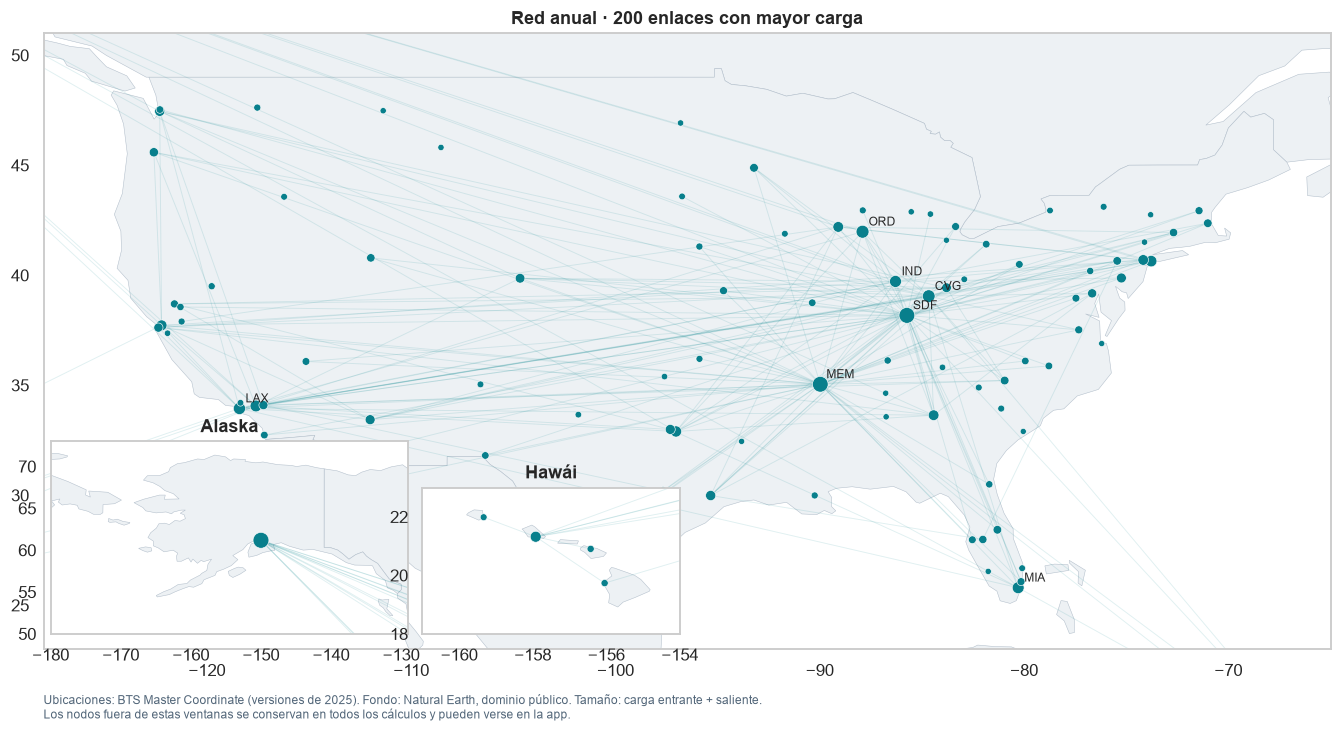

In [12]:
# Mapa con la cartografía local de Natural Earth; recuadros para Alaska y Hawái.
import json
world = json.loads(WORLD_GEOJSON.read_text())
fig = plt.figure(figsize=(13, 7))
ax = fig.add_axes([.06, .12, .9, .8]); ax_ak = fig.add_axes([.065, .14, .25, .25]); ax_hi = fig.add_axes([.325, .14, .18, .19])
lookup = airports.set_index('airport_id')
for axis, bounds, title in [(ax, (-128, -65, 23, 51), 'Red anual · 200 enlaces con mayor carga'),
                            (ax_ak, (-180, -129, 50, 73), 'Alaska'), (ax_hi, (-161, -154, 18, 23), 'Hawái')]:
    for feature in world['features']:
        geom = feature['geometry']
        polygons = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
        for polygon in polygons:
            xy = np.array(polygon[0]); axis.fill(xy[:, 0], xy[:, 1], color='#edf1f4', edgecolor='#b4c0cc', lw=.35, zorder=0)
    for row in networks['annual']['edges'].nlargest(200, 'freight_lb').itertuples():
        a, b = lookup.loc[row.u], lookup.loc[row.v]
        if abs(a.lon-b.lon) < 180:
            axis.plot([a.lon, b.lon], [a.lat, b.lat], color='#0d8a92', alpha=.13, lw=.6, zorder=1)
    axis.scatter(airports.lon, airports.lat, s=8+100*np.sqrt(airports.annual_freight_lb/airports.annual_freight_lb.max()),
                 c='#087f8c', edgecolor='white', lw=.4, zorder=2)
    axis.set(xlim=bounds[:2], ylim=bounds[2:], title=title)
    axis.grid(False)
for row in airports.head(8).itertuples():
    if -128 < row.lon < -65 and 23 < row.lat < 51:
        ax.annotate(row.code, (row.lon, row.lat), xytext=(4, 4), textcoords='offset points', fontsize=8)
fig.text(.06, .03, 'Ubicaciones: BTS Master Coordinate (versiones de 2025). Fondo: Natural Earth, dominio público. '
         'Tamaño: carga entrante + saliente.\nLos nodos fuera de estas ventanas se conservan en todos los cálculos y pueden verse en la app.',
         fontsize=8, color='#526679')
plt.savefig(FIG/'02_mapa_red.png', bbox_inches='tight', dpi=160); plt.show()

### **4.2. Análisis exploratorio de la red**

El artículo pasa directamente de construir la red a medir su robustez. Esta sección
responde antes cuatro preguntas sobre la red que se va a perturbar, porque de ellas
depende cómo leer la sinergia: (1) medidas globales y locales; (2) centralidades;
(3) a qué modelo de red se parece; (4) si hay comunidades.

**Medidas globales y locales.**

- **Densidad**: fracción de las 4.950 parejas posibles que tienen enlace. En redes de
  transporte suele ser menor al 1 %; un valor alto indica caminos cortos y mucha
  redundancia.
- **Distancia media y diámetro**: número mínimo de escalas entre dos aeropuertos,
  promediado sobre todas las parejas, y su máximo. Un diámetro 3 significa que desde
  cualquier aeropuerto se llega a cualquier otro con dos escalas como máximo.
- **Agrupamiento y transitividad.** Ambas cuentan triángulos, pero promedian
  distinto. El **agrupamiento medio** calcula, para cada aeropuerto, qué fracción de
  sus parejas de vecinos están conectadas entre sí, y promedia: cada aeropuerto pesa
  igual. La **transitividad** divide el triple del número de triángulos de toda la
  red entre el número de tripletas conectadas: los hubs pesan más porque tienen
  muchas más tripletas. Si la transitividad es menor que el agrupamiento medio, los
  vecindarios de los hubs están menos conectados que los de los aeropuertos
  pequeños, que es la firma del modelo *hub-and-spoke*.
- **Asortatividad de grado**: correlación entre los grados de los dos extremos de
  cada enlace. Negativa significa grandes conectados con pequeños (*hub-and-spoke*);
  positiva, grandes conectados entre sí.
- **Núcleo k-core**: el subgrafo más grande en el que todos los aeropuertos tienen
  al menos *k* conexiones con otros miembros del mismo subgrafo. Se obtiene
  retirando de forma repetida a los que tienen menos de *k*. La tabla informa el
  mayor *k* posible (`núcleo k`) y cuántos aeropuertos lo forman (`tamaño del
  núcleo`): es el núcleo denso de la red, y el resto es su periferia.

**Centralidades**, todas sobre la red binaria: **grado** (número de aeropuertos
conectados directamente), **intermediación** (número de caminos mínimos entre otras
parejas que pasan por el aeropuerto), **cercanía** ($C_i = (N-1)/\sum_j d_{ij}$, el
inverso del número medio de escalas hasta los demás) y **autovector** (importancia
por estar conectado con aeropuertos a su vez importantes).

**Tipo de red.** El curso distingue tres modelos por tres propiedades:

| Modelo | Agrupamiento | Caminos | Hubs |
|---|---|---|---|
| Aleatoria (Erdős–Rényi) | Bajo | Cortos | No: grados homogéneos |
| Mundo pequeño (Watts–Strogatz) | Alto | Cortos | No: grados homogéneos |
| Preferencial (Barabási–Albert) | Alto | Cortos | Sí: grados heterogéneos |

Para ubicar la red se generan 30 redes de cada modelo con los mismos 100 nodos y
casi los mismos enlaces (Barabási–Albert con el parámetro que iguala los enlaces;
Watts–Strogatz con el grado medio de la red y recableado 0,1) y se comparan las tres
propiedades. Las etiquetas se fijan respecto a la red aleatoria: agrupamiento
**alto** si es al menos 1,2 veces el aleatorio; caminos **largos** si la distancia
media supera en más de un 20 % la aleatoria; **hubs** si la desviación típica del
grado es al menos el doble de la aleatoria. El modelo más cercano es el de menor
distancia relativa en las tres propiedades.

**Comunidades.** Se buscan con el método de Louvain, que maximiza la **modularidad
Q**: la fracción de enlaces dentro de los grupos menos la que cabría esperar al azar
con los mismos grados. Q va de −0,5 a 1, y por encima de 0,3 suele hablarse de una
estructura de comunidades clara. Como Louvain depende de una semilla aleatoria, se
ejecuta 20 veces y se informa la **NMI** media entre las particiones obtenidas: 1 si
coinciden siempre, 0 si no se parecen.

In [13]:
EXPLORACION = OUT/'exploracion'
exploration_base = explore_base_networks(networks, airports, EXPLORACION, runs=20, replicas=30, seed=SEED)
annual_structure = exploration_base[('annual', 'base')]
structure_summary = pd.read_csv(EXPLORACION/'resumen_estructura_base.csv')
display(structure_summary[['period', 'n_edges', 'density', 'mean_degree', 'max_degree', 'diameter',
                           'average_path_length', 'average_clustering', 'transitivity',
                           'degree_assortativity', 'max_core', 'max_core_size']]
        .rename(columns={'period': 'período', 'n_edges': 'enlaces', 'density': 'densidad',
                         'mean_degree': 'grado medio', 'max_degree': 'grado máximo', 'diameter': 'diámetro',
                         'average_path_length': 'distancia media', 'average_clustering': 'agrupamiento medio',
                         'transitivity': 'transitividad', 'degree_assortativity': 'asortatividad',
                         'max_core': 'núcleo k', 'max_core_size': 'tamaño del núcleo'}))

,período,enlaces,densidad,grado medio,grado máximo,diámetro,distancia media,agrupamiento medio,transitividad,asortatividad,núcleo k,tamaño del núcleo
0,annual,2441,0.49313,48.82000,89,3,1.50828,0.74564,0.67936,-0.16105,36,53
1,T1,1818,0.36727,36.36000,89,3,1.64444,0.73077,0.61760,-0.21984,31,38
2,T2,1879,0.37960,37.58000,88,3,1.63455,0.74266,0.62992,-0.23152,34,38
3,T3,1947,0.39333,38.94000,88,3,1.61758,0.73141,0.64018,-0.21911,34,38
4,T4,1994,0.40283,39.88000,88,3,1.60606,0.72925,0.62394,-0.21521,32,41


**Interpretación de las medidas globales y locales.** La densidad anual es 0,49: cada
aeropuerto conecta directamente con la mitad de los demás. Es altísima para una red
de transporte y se explica por dos decisiones: solo entran los 100 mayores y basta un
vuelo en el año para crear el enlace. La distancia media es 1,51 escalas y el
diámetro es 3; 91 de los 100 aeropuertos llegan a todos los demás con una escala
como máximo. Por eso perder uno o dos aeropuertos cambia las eficiencias apenas en
milésimas (sección 6). El agrupamiento medio (0,75) supera a la transitividad
(0,68): los aeropuertos pequeños conectan casi solo con hubs que están conectados
entre sí, mientras que los hubs sirven a muchos aeropuertos que no se conectan entre
ellos. La asortatividad es negativa (−0,16), otra señal *hub-and-spoke*. El núcleo
k-core reúne 53 aeropuertos con al menos 36 conexiones dentro del núcleo. Los
trimestres, con menos enlaces, repiten el patrón con un núcleo más pequeño.

**Centralidades.** La tabla muestra los diez primeros aeropuertos según cada
centralidad, junto a los diez de mayor carga incidente, y después la correlación de
Spearman entre centralidades: indica si dos medidas **ordenan los aeropuertos de la
misma forma**, es decir, si son redundantes.

In [14]:
centralities_annual = annual_structure['centralities']
top10 = top_by_centrality(centralities_annual, top_k=10)
by_freight = (networks['annual']['nodes'].merge(airports[['airport_id', 'code']], on='airport_id')
              .sort_values(['freight_lb', 'code'], ascending=[False, True]).head(10))
top10.insert(0, 'Carga incidente (millones de lb)', [f'{r.code} ({r.freight_lb/1e6:,.0f})' for r in by_freight.itertuples()])
display(top10)
labels_es = {'degree': 'grado', 'betweenness': 'intermediación', 'closeness': 'cercanía', 'eigenvector': 'autovector'}
print('Correlación de Spearman entre centralidades (red anual):')
display(annual_structure['centrality_spearman'].rename(index=labels_es, columns=labels_es).round(3))
ranks = centralities_annual.set_index('id')
for code_ in ['RFD', 'ATL', 'ANC']:
    print(f"{code_}: puesto {ranks.loc[code_, 'rank_degree']:g} por grado y {ranks.loc[code_, 'rank_betweenness']:g} por intermediación "
          '(un puesto con decimal indica empate).')

,Carga incidente (millones de lb),Grado,Intermediación,Cercanía,Autovector
puesto,,,,,
1,"ANC (5,608)",DFW (89),ORD (124.7),DFW (0.908),DFW (0.153)
2,"SDF (5,456)",MEM (89),MEM (118.3),MEM (0.908),MEM (0.152)
3,"MEM (5,348)",ORD (89),SDF (105.1),ORD (0.908),ORD (0.152)
4,"ORD (2,235)",SDF (87),DFW (103.0),SDF (0.892),DEN (0.148)
5,"CVG (2,077)",DEN (85),DEN (93.8),DEN (0.876),SDF (0.147)
6,"LAX (1,725)",ATL (81),PHX (92.1),ATL (0.846),ATL (0.146)
7,"IND (1,598)",PHX (81),RFD (72.8),PHX (0.846),PHX (0.141)
8,"MIA (1,527)",LAX (78),LAX (70.2),LAX (0.825),LAX (0.139)
9,"ONT (1,467)",BWI (76),ONT (65.5),BWI (0.811),BWI (0.139)


Correlación de Spearman entre centralidades (red anual):


,grado,intermediación,cercanía,autovector
grado,1.00000,0.96400,1.00000,0.99600
intermediación,0.96400,1.00000,0.96400,0.94400
cercanía,1.00000,0.96400,1.00000,0.99600
autovector,0.99600,0.94400,0.99600,1.00000


RFD: puesto 26.5 por grado y 7 por intermediación (un puesto con decimal indica empate).
ATL: puesto 6.5 por grado y 12 por intermediación (un puesto con decimal indica empate).
ANC: puesto 51 por grado y 45 por intermediación (un puesto con decimal indica empate).


**Interpretación.** ORD, MEM, DFW y SDF encabezan todas las centralidades. Grado,
cercanía y autovector ordenan los aeropuertos casi igual (Spearman ≥ 0,99). La
cercanía coincide con el grado (Spearman 1,000) por una razón concreta: casi todo
está a una o dos escalas, de modo que la suma de distancias de un aeropuerto es
aproximadamente 198 menos su grado; en esta red la cercanía no aporta información
distinta del grado. La intermediación es la única que ordena algo distinto
(Spearman 0,96): RFD está hacia el puesto 26 por grado (empatado con otro
aeropuerto) pero es 7.º por intermediación, porque conecta aeropuertos que no
comparten vecinos, mientras que ATL comparte los puestos 6.º y 7.º por grado y es
12.º por intermediación. El volumen tampoco coincide con la estructura: ANC es el primero por
carga, sobre todo internacional en tránsito, pero el 51.º por grado. Esta
redundancia entre centralidades justifica que la regresión de la sección 8 use solo
grado e intermediación, igual que el artículo.

**Tipo de red.** La tabla compara la red con la media de las 30 redes de cada modelo
en las tres propiedades del curso, y la figura muestra además la distribución de
grado.

,Agrupamiento medio,Distancia media (escalas),Desviación típica del grado,Grado máximo,Agrupamiento,Caminos,Hubs
Red observada,0.74564,1.50828,21.37914,89,alto,cortos,sí
Aleatoria (Erdős–Rényi),0.49272,1.50687,4.78210,60.93333,bajo,cortos,no
Mundo pequeño (Watts–Strogatz),0.61923,1.51515,2.10145,53.43333,alto,cortos,no
Preferencial (Barabási–Albert),0.65941,1.50788,19.54445,92.66667,alto,cortos,sí


Parámetros de los modelos: {'erdos_renyi': {'n': 100, 'm': 2441}, 'watts_strogatz': {'n': 100, 'k': 48, 'p': 0.1}, 'barabasi_albert': {'n': 100, 'm': 42}}
Perfil del curso que coincide: barabasi_albert | modelo simulado más cercano: barabasi_albert


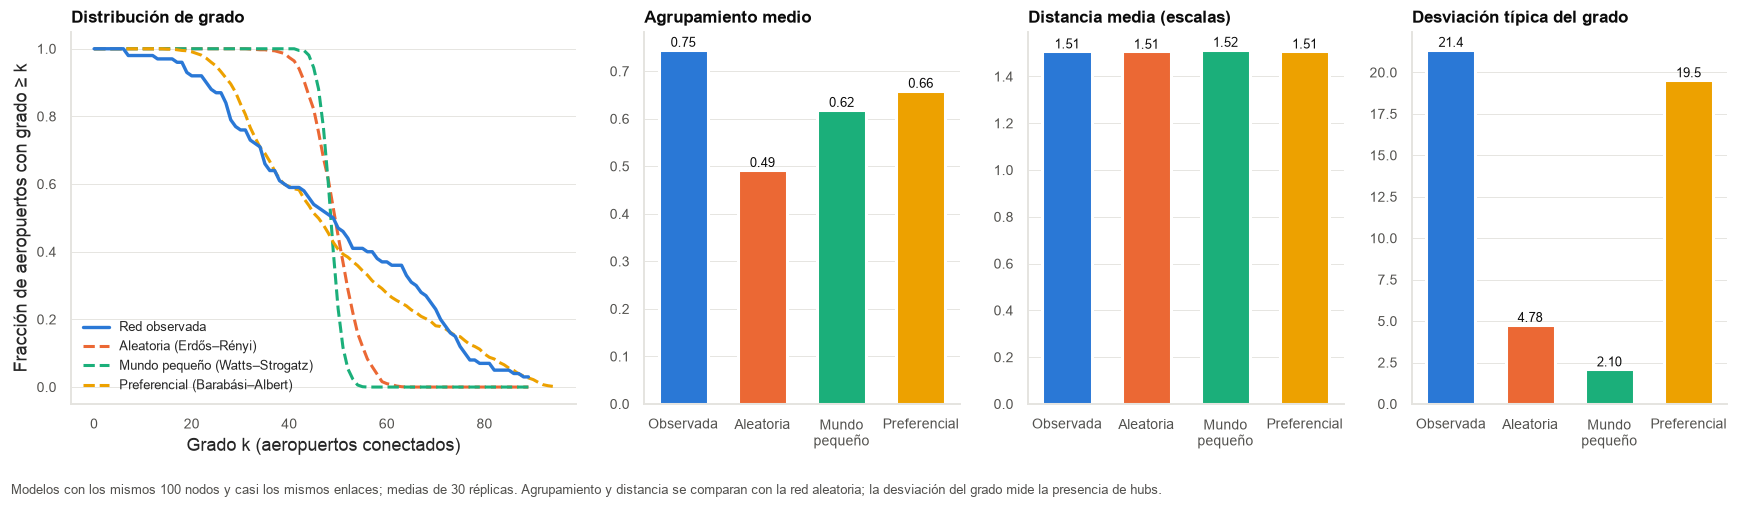

In [15]:
display(model_table(annual_structure))
models_annual = annual_structure['models']
print('Parámetros de los modelos:', {k: v['parameters'] for k, v in models_annual['models'].items()})
print('Perfil del curso que coincide:', models_annual['course_match'], '| modelo simulado más cercano:', models_annual['closest_model'])
_ = plot_degree_and_models(annual_structure, FIG/'16_distribucion_grado_modelos.png')

**Interpretación.** En las tres propiedades del curso:

- **Agrupamiento:** la red (0,75) supera a los tres modelos y está muy por encima de
  la red aleatoria (0,49).
- **Caminos:** todos son cortos (unas 1,51 escalas). En una red tan densa esta
  propiedad no distingue modelos.
- **Hubs:** la desviación típica del grado (21,4) es más de cuatro veces la de la red
  aleatoria y unas diez veces la del mundo pequeño, y muy parecida a la de
  Barabási–Albert (19,5).

La red tiene, por tanto, el perfil **preferencial (Barabási–Albert)**: agrupamiento
alto, caminos cortos y hubs. Es también el modelo simulado más cercano, y los cuatro
trimestres dan la misma conclusión. Dos matices: la red agrupa todavía más que
Barabási–Albert, y su distribución de grado es ancha y casi plana entre 20 y 90
conexiones, no una cola larga con pocos nodos enormes.

Por eso **no se ajusta una ley de potencia**. Una ley de potencia describe una cola
que se extiende por varios órdenes de magnitud; aquí el grado va de 6 a 89, un solo
orden de magnitud, y ningún aeropuerto puede superar 99 conexiones. Con 100 nodos
cualquier ajuste sería poco fiable (Clauset, Shalizi y Newman, 2009, recomiendan al
menos dos órdenes de magnitud). La red tiene hubs, pero no se describe como libre de
escala.

**Comunidades.**

Red binaria anual: 3 comunidades · modularidad Q = 0.121 · NMI media entre 20 ejecuciones = 0.70 · comunidades por ejecución: [3, 4]


,comunidad,tamaño,enlaces internos,fracción del grado dentro del grupo,principales aeropuertos
0,1,45,681,0.59012,"MEM, ORD, SDF, ATL, BWI, JFK, EWR, PHL"
1,2,37,448,0.50938,"DFW, DEN, PHX, LAX, MSP, SEA, LAS, ONT"
2,3,18,98,0.24049,"IAH, STL, CVG, MCI, AUS, MSY, AFW, SAT"


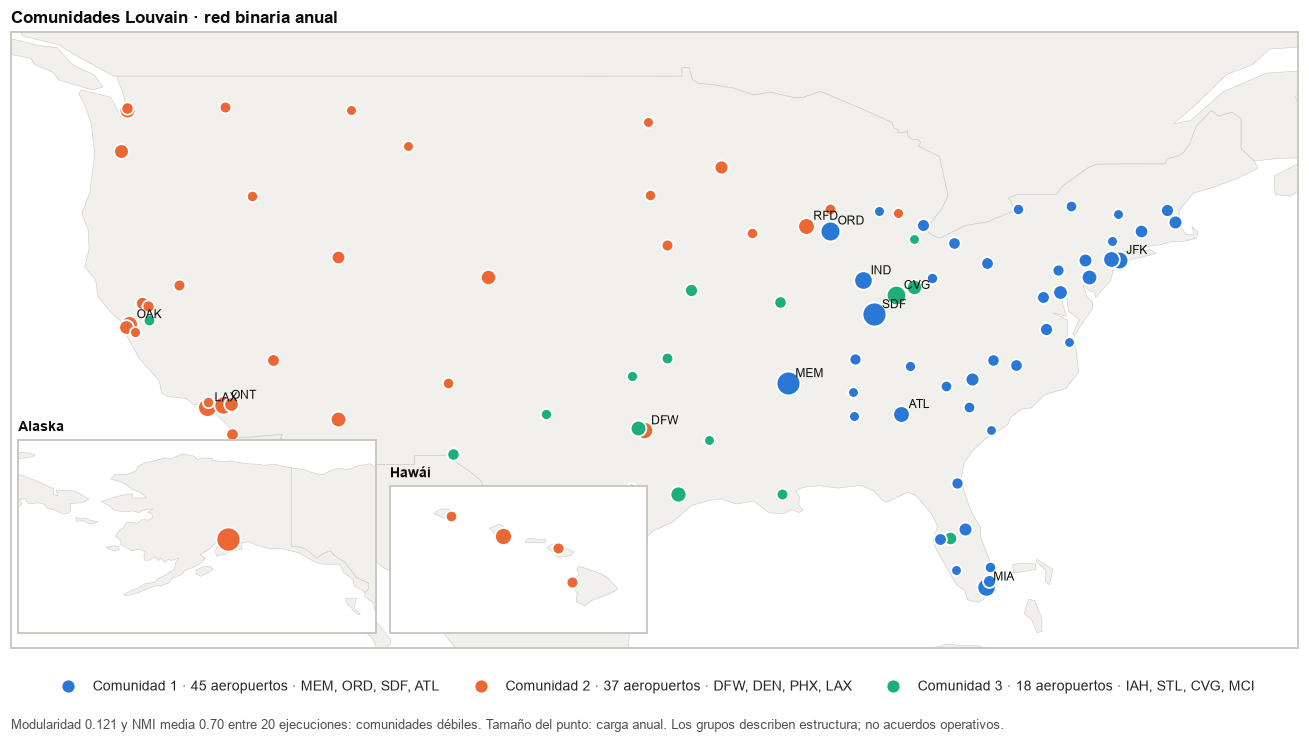

In [16]:
def community_frame(block):
    return pd.DataFrame([{'comunidad': c['id']+1, 'tamaño': c['size'], 'enlaces internos': c['internal_edges'],
                          'fracción del grado dentro del grupo': c['internal_share'],
                          'principales aeropuertos': ', '.join(c['members'][:8])} for c in block['communities']])


communities_annual = annual_structure['communities']
print(f"Red binaria anual: {communities_annual['n_communities']} comunidades · modularidad Q = {communities_annual['modularity']:.3f} · "
      f"NMI media entre {communities_annual['runs']} ejecuciones = {communities_annual['nmi_mean']:.2f} · "
      f"comunidades por ejecución: {communities_annual['n_communities_by_run']}")
display(community_frame(communities_annual))
_ = plot_community_map(annual_structure, airports, WORLD_GEOJSON, FIG/'17_comunidades_mapa.png')

**Interpretación.** Louvain encuentra tres grupos con modularidad 0,12, muy por debajo
del umbral habitual de 0,3, y la partición cambia bastante de una ejecución a otra
(NMI 0,70; algunas ejecuciones dan cuatro grupos). Hay, por tanto, **comunidades
débiles**: grupos con algo más de enlaces internos de lo esperado, pero sin fronteras
claras. Los grupos coinciden en parte con la geografía (este, oeste y centro-sur),
lo que es una coincidencia descriptiva: no se infieren acuerdos ni rutas operativas a
partir de ella.

**Síntesis de la exploración.** La red que se va a perturbar es densa, de caminos
muy cortos, con hubs y un patrón *hub-and-spoke*, del tipo preferencial, sin
comunidades marcadas. En una red así casi todo tiene alternativas, por lo que el
interés está en las parejas cuyo fallo conjunto elimina alternativas que cada una
cubría de la otra: eso es lo que mide la sinergia.

## **5. Medidas de robustez**

### **5.1. Las tres medidas: definición e intuición**

En todas las fórmulas, $N$ es el número de aeropuertos de la red, $d_{ij}$ el número
mínimo de escalas entre $i$ y $j$, y $\lambda_1, \dots, \lambda_N$ los autovalores de
la matriz de adyacencia.

**Eficiencia global** (ecuación 1 del artículo; Latora y Marchiori, 2001):

$$E_{glob}(G)=\frac{1}{N(N-1)}\sum_{i\neq j}\frac{1}{d_{ij}}$$

Promedia el inverso del número de escalas sobre todas las parejas. Vale 1 si todos
están conectados directamente y baja cuando los caminos se alargan; una pareja sin
camino aporta 0. *Intuición:* qué tan rápido, en número de escalas, llega la carga
de cualquier aeropuerto a cualquier otro.

**Eficiencia local** (ecuaciones 2 y 3):

$$E_{loc}(G)=\frac{1}{N}\sum_{i=1}^{N}E_{glob}(G_i)$$

donde $G_i$ es el subgrafo formado por los vecinos de $i$, sin $i$. Un aeropuerto con
menos de dos vecinos aporta 0. *Intuición:* si un aeropuerto desaparece, ¿sus vecinos
siguen comunicados entre sí a corta distancia?

**Conectividad natural** (ecuación 4; Wu y coautores, 2010):

$$\bar\lambda(G)=\ln\left(\frac{1}{N}\sum_{k=1}^{N}e^{\lambda_k}\right)$$

Equivale a contar todos los **recorridos cerrados** de cualquier longitud que ofrece
la red, ponderados por $1/k!$ según su longitud $k$. *Intuición:* cuántas
alternativas redundantes existen; crece con la redundancia aunque los caminos
mínimos no cambien.

### **5.2. Por qué estas tres medidas en una red de aeropuertos**

Zhou y Razavi (2026) las eligen porque describen tres formas distintas de fallar
(su Tabla 1), y la red densa y *hub-and-spoke* de la sección 4.2 explica por qué las
tres son pertinentes aquí:

- **Eficiencia global: alcance del sistema.** Un envío entre dos aeropuertos sin
  vuelo directo pasa por uno o más hubs. La eficiencia global cae cuando los desvíos
  se alargan o dejan de existir. Representa el fallo de alcance nacional: perder un
  hub obliga a rutas con más escalas o deja parejas sin camino. Es la medida clásica
  de Latora y Marchiori (2001) y la más usada en estudios de ataques a redes de
  transporte.
- **Eficiencia local: redundancia del entorno de cada aeropuerto.** Mide la
  capacidad de re-enrutar a corta distancia cuando un aeropuerto desaparece. Los
  aeropuertos alimentadores de un hub quedan comunicados solo si tienen enlaces
  entre ellos o comparten otro hub. Captura fallos regionales que el promedio
  nacional diluye.
- **Conectividad natural: redundancia total de recorridos.** Es sensible a la
  pérdida de enlaces aunque los caminos mínimos no cambien: en la sección 9.4 se
  verá que SDF–SEA no alarga ningún camino mínimo y sin embargo pierde redundancia
  espectral.

Juntas evitan depender de un solo tipo de fallo. Sus límites también son
compartidos: miden una red binaria, sin capacidad, horarios ni operadores, y los
caminos agregados pueden mezclar compañías sin acuerdos de transferencia.
**Equivalencia de términos:** lo que aquí se llama *impacto* o *daño* de retirar
nodos es la *vitalidad de robustez* del artículo (su ecuación 5); la *sinergia* es
su ecuación 6.

### **5.3. Implementación y validación**

Calcular 24.750 fallos dobles exige evaluar las tres medidas unas 25 mil veces, así
que la implementación es propia y acelerada con numba: obtiene exactamente las
distancias 1 y 2 mediante intersecciones de vecinos codificadas en bits y usa
búsqueda en anchura solo cuando necesita distancias mayores. No aproxima caminos.
La fórmula espectral usa `logsumexp` para estabilidad numérica. El código de las
dos funciones centrales es el siguiente.

In [17]:
show_code(_efficiencies, robustness_metrics)

@njit
def _efficiencies(adj):
    n = len(adj)
    if n == 0:
        return 0.0, 0.0
    r0 = np.zeros(n, dtype=np.uint64)
    r1 = np.zeros(n, dtype=np.uint64)
    a0, a1 = np.uint64(0), np.uint64(0)
    for j in range(n):
        if j < 64:
            a0 |= np.uint64(1) << np.uint64(j)
        else:
            a1 |= np.uint64(1) << np.uint64(j-64)
        for i in range(n):
            if adj[i,j]:
                if j < 64:
                    r0[i] |= np.uint64(1) << np.uint64(j)
                else:
                    r1[i] |= np.uint64(1) << np.uint64(j-64)
    global_eff = _efficiency_bits(r0,r1,a0,a1)
    local_eff = 0.0
    for i in range(n):
        local_eff += _efficiency_bits(r0,r1,r0[i],r1[i])
    return global_eff, local_eff/n


def robustness_metrics(adj):
    """Ecuaciones 1–4; denominadores corresponden al grafo restante.

    A es binaria, simétrica, sin diagonal. Los pares desconectados aportan
    cero a eficiencia. Para 0 nodos definimos las tres métricas como cero.
    El cálculo por conjuntos soporta hasta 128 nodos (proyecto:100).
    """
    a = np.asarray(adj,dtype=np.bool_)
    assert a.ndim == 2 and a.shape[0] == a.shape[1] and len(a) <= 128
    assert np.array_equal(a,a.T) and not np.diag(a).any()
    if not len(a):
        return np.zeros(3)
    g,l = _efficiencies(a)
    values = eigvalsh(a.astype(float), check_finite=False)
    natural = float(logsumexp(values)-np.log(len(a)))
    return np.array([g,l,natural])

La validación compara la implementación con NetworkX en 19 grafos de solución
conocida (conectados, desconectados, aleatorios y casos límite). Después se
calculan las tres medidas de las cinco redes reales antes de cualquier fallo.

**Sobre los denominadores:** tras eliminar un nodo las medidas se calculan sobre 99
nodos y tras eliminar dos, sobre 98. Por eso retirar un nodo periférico puede
*aumentar* una eficiencia promedio y producir un impacto negativo. Los signos se
conservan; estas cantidades no son porcentajes de carga perdida.

In [18]:
validation_metrics = verify_metrics()
print(validation_metrics)
baseline_table = pd.DataFrame({PERIODS[p]: robustness_metrics(n['adj']) for p, n in networks.items()},
                              index=['eficiencia global', 'eficiencia local', 'conectividad natural']).T
print('Medidas de las cinco redes reales antes de cualquier fallo:')
display(baseline_table)

{'graphs_checked': 19, 'networkx_agreement': True, 'diamond_global_synergy': 0.8333333333333334}
Medidas de las cinco redes reales antes de cualquier fallo:


,eficiencia global,eficiencia local,conectividad natural
Año 2025,0.74633,0.87280,52.72956
Enero–marzo,0.68168,0.86511,42.98479
Abril–junio,0.68744,0.87117,44.38344
Julio–septiembre,0.69485,0.86031,45.59081
Octubre–diciembre,0.69993,0.86453,45.46467


**Interpretación.** La implementación coincide con NetworkX en los 19 grafos de
prueba. En la red anual la eficiencia global es 0,746 (casi todo a una o dos
escalas) y la local 0,873 (los vecinos de cada aeropuerto siguen muy conectados sin
él). Los trimestres, con menos enlaces, tienen valores algo menores.

## **6. Simulación de fallos**

### **6.1. Impacto y sinergia**

Para una medida $M$ (cualquiera de las tres), el **impacto** de retirar el aeropuerto
$i$, el de retirar la pareja $\{i,j\}$ y la **sinergia** de la pareja son:

$$v_i=M(G)-M(G\setminus\{i\}),\qquad v_{ij}=M(G)-M(G\setminus\{i,j\}),\qquad S_{ij}=v_{ij}-v_i-v_j$$

La sinergia es lo que el fallo conjunto daña **por encima de la suma** de los dos
fallos separados:

- **Positiva:** juntos dañan más de lo que sumarían. Cada aeropuerto cubría
  alternativas del otro, y al caer ambos esas alternativas desaparecen a la vez.
- **Negativa:** sus daños se solapan; parte del daño ya lo causaba cualquiera de los
  dos.

**Por qué un enlace directo baja la sinergia.** Si $i$ y $j$ están conectados, el
enlace $i$–$j$ y los recorridos que pasan por él se destruyen al retirar $i$ y
también al retirar $j$: cuentan dos veces en $v_i+v_j$, pero una sola vez en
$v_{ij}$. Por eso las parejas conectadas tienden a tener sinergia menor; las
secciones 8 y 9 vuelven sobre este mecanismo.

### **6.2. Todos los fallos de las cinco redes**

En cada una de las cinco redes (anual y cuatro trimestres) se ejecutan los 100
fallos individuales y los 4.950 dobles. Hay que repetirlos en cada trimestre porque
cada uno tiene enlaces distintos. Los resultados se guardan en cachés cuya huella
depende de la adyacencia y de la versión del algoritmo: si cambian los datos, se
recalculan. El código de la simulación es el siguiente.

In [19]:
show_code(simulate_period)

def simulate_period(adj, cache_path, use_cache=True, verbose=True):
    """Todas las eliminaciones individuales y todos los pares, con caché validada."""
    fingerprint = hashlib.sha256(ALGORITHM_VERSION.encode()+np.ascontiguousarray(adj).tobytes()).hexdigest()
    cache_path = Path(cache_path)
    if use_cache and cache_path.exists():
        with np.load(cache_path,allow_pickle=False) as z:
            if str(z['fingerprint']) == fingerprint:
                if verbose: print(f'{cache_path.stem}: caché verificada',flush=True)
                return {k:z[k].copy() for k in ['baseline','single_impact','pair_indices','joint_impact','synergy']}
    t0 = time.perf_counter()
    n = len(adj)
    baseline = robustness_metrics(adj)
    single = np.zeros((n,3))
    with threadpool_limits(limits=1):
        for i in range(n):
            keep = np.arange(n) != i
            single[i] = baseline-robustness_metrics(adj[np.ix_(keep,keep)])
        pairs = np.array(list(combinations(range(n),2)),dtype=int)
        joint = np.zeros((len(pairs),3))
        for k,(i,j) in enumerate(pairs):
            keep = (np.arange(n)!=i)&(np.arange(n)!=j)
            joint[k] = baseline-robustness_metrics(adj[np.ix_(keep,keep)])
            if verbose and (k+1)%1000 == 0:
                print(f'{cache_path.stem}: {k+1}/{len(pairs)} pares ({time.perf_counter()-t0:.1f} s)',flush=True)
    synergy = joint-single[pairs[:,0]]-single[pairs[:,1]]
    result = dict(baseline=baseline,single_impact=single,pair_indices=pairs,
                  joint_impact=joint,synergy=synergy)
    assert all(np.isfinite(v).all() for v in result.values())
    cache_path.parent.mkdir(parents=True,exist_ok=True)
    temp = cache_path.with_suffix('.tmp')
    with open(temp,'wb') as f:
        np.savez_compressed(f,fingerprint=fingerprint,**result)
    temp.replace(cache_path)
    if verbose: print(f'{cache_path.stem}: terminado en {time.perf_counter()-t0:.1f} s',flush=True)
    return result

In [20]:
started = time.perf_counter()
simulations = {p: simulate_period(n['adj'], CACHE/f'{p}.npz', use_cache=USAR_CACHE) for p, n in networks.items()}
elapsed = time.perf_counter()-started
for p, s in simulations.items():
    assert len(s['pair_indices']) == TOP_N*(TOP_N-1)//2
    np.testing.assert_allclose(s['synergy'], s['joint_impact']-s['single_impact'][s['pair_indices'][:, 0]]
                               - s['single_impact'][s['pair_indices'][:, 1]])
print(f'Tiempo de esta ejecución (puede usar caché): {elapsed:.2f} segundos')
example_pair = simulations['annual']['pair_indices'][0]
i, j = example_pair
print(f'Ejemplo: {airports.iloc[i].code} + {airports.iloc[j].code} en la red anual')
display(pd.DataFrame({'impacto de ' + airports.iloc[i].code: simulations['annual']['single_impact'][i],
                      'impacto de ' + airports.iloc[j].code: simulations['annual']['single_impact'][j],
                      'impacto conjunto': simulations['annual']['joint_impact'][0],
                      'sinergia': simulations['annual']['synergy'][0]},
                     index=['eficiencia global', 'eficiencia local', 'conectividad natural']))

annual: caché verificada


T1: caché verificada


T2: caché verificada


T3: caché verificada


T4: caché verificada


Tiempo de esta ejecución (puede usar caché): 0.01 segundos
Ejemplo: ANC + SDF en la red anual


,impacto de ANC,impacto de SDF,impacto conjunto,sinergia
eficiencia global,-0.00008,0.00394,0.00389,0.00003
eficiencia local,-0.00106,0.00276,0.00166,-0.00004
conectividad natural,0.48581,1.25613,1.73715,-0.00478


**Interpretación.** La tabla muestra, para la primera pareja de la lista (ANC y SDF),
los dos impactos individuales, el conjunto y la sinergia de cada medida. Las
magnitudes de las eficiencias son pequeñas (milésimas) porque la red es densa y
perder dos nodos de cien cambia poco el promedio; la conectividad natural se mueve en
otra escala. Cada medida tiene su propia escala: por eso hace falta normalizar antes
de combinarlas.

## **7. Índice compuesto de sinergia**

### **7.1. Normalización y pesos por entropía**

El índice **no ordena las parejas por el daño total que causan, sino por su
sinergia**: el daño adicional de su fallo conjunto. Las tres sinergias no son
comparables entre sí (una está en milésimas y otra en unidades), así que el
artículo (ecuaciones 7 a 12) las pone en la misma escala y las combina. Para cada
medida $m$ y pareja $ij$, con $n = 4.950$ parejas:

1. **Normalizar** por el máximo absoluto de la medida: $\tilde S^{(m)}_{ij} = S^{(m)}_{ij}/\max|S^{(m)}|$. Cada valor queda entre −1 y 1.
2. Convertir las magnitudes en una distribución, $p^{(m)}_{ij} = |\tilde S^{(m)}_{ij}| / \sum |\tilde S^{(m)}|$, y calcular su **entropía** normalizada, $e_m = -\frac{1}{\ln n}\sum_{ij} p^{(m)}_{ij}\ln p^{(m)}_{ij}$.
3. Asignar a cada medida el **peso** $w_m = (1-e_m)/\sum_k (1-e_k)$. Una medida en la
   que todas las parejas tienen casi la misma sinergia tiene entropía alta y peso
   bajo, porque apenas distingue unas parejas de otras.
4. Sumar las sinergias normalizadas **con su signo**: $I_{ij} = \sum_m w_m\,\tilde S^{(m)}_{ij}$.

**Rango del índice.** Cada sinergia normalizada está entre −1 y 1 y los pesos son
positivos y suman 1, así que el índice es un promedio ponderado y **va de −1 a 1**.
Solo vale 1 si una pareja es la máxima en las tres medidas. Positivo significa que
juntos dañan más que la suma; negativo, que sus daños se solapan. No es un
porcentaje ni una probabilidad, y los pesos reflejan la dispersión de los datos, no
una importancia operativa elegida por expertos.

In [21]:
show_code(entropy_composite)

def entropy_composite(synergies, scales=None, weights=None):
    """Ecs.7–12: escala máximo absoluto; probabilidades con magnitudes.

    Conserva signo en el índice final. Columnas nulas o constantes en
    magnitud tienen peso informativo cero; si todas son degeneradas, pesos0.
    """
    s = np.asarray(synergies,dtype=float)
    scales = np.max(np.abs(s),axis=0) if scales is None else np.asarray(scales)
    z = np.divide(s,scales,out=np.zeros_like(s),where=scales>1e-14)
    masses = np.abs(z).sum(axis=0)
    p = np.divide(np.abs(z),masses,out=np.zeros_like(z),where=masses>0)
    logs = np.zeros_like(p)
    np.log(p,out=logs,where=p>0)
    entropy = -(p*logs).sum(axis=0)/np.log(len(s))
    info = np.where(masses>1e-14,np.maximum(0,1-entropy),0)
    info[info < 1e-12] = 0
    if weights is None:
        weights = info/info.sum() if info.sum()>0 else np.zeros(s.shape[1])
    return {'score':z@weights,'normalized':z,'scales':scales,
            'weights':np.asarray(weights),'entropy':entropy}

### **7.2. Ranking anual**

La primera tabla muestra el **peso de cada medida en el índice** de cada período
(cada fila suma 1); no son valores de eficiencia. La segunda, las veinte parejas con
mayor índice anual con su sinergia por medida, que es lo que se ordena, y su daño
conjunto, que se muestra solo como contexto.

,peso eficiencia global,peso eficiencia local,peso conectividad natural,suma
Año 2025,0.27144,0.42785,0.30071,1.00000
Enero–marzo,0.18378,0.50982,0.30640,1.00000
Abril–junio,0.12775,0.67654,0.19571,1.00000
Julio–septiembre,0.26050,0.48259,0.25691,1.00000
Octubre–diciembre,0.23851,0.55121,0.21028,1.00000


,puesto,a,b,AirportID a,AirportID b,enlace directo,índice,sinergia ef. global,sinergia ef. local,sinergia conect. natural,daño conjunto ef. global,daño conjunto ef. local,daño conjunto conect. natural
114,1.00000,SDF,SEA,14730,14747,False,0.68352,0.00019,0.00051,0.04878,0.00673,0.00448,2.35015
121,2.00000,SDF,SFO,14730,14771,False,0.59114,0.00017,0.00039,0.04450,0.00610,0.00381,2.22347
197,3.00000,MEM,ORD,13244,13930,True,0.47190,0.00033,0.00028,0.01183,0.00887,0.00675,2.69691
799,4.00000,ONT,IAD,13891,12264,False,0.41706,0.00014,0.00021,0.03410,0.00431,0.00196,1.85507
585,5.00000,IND,RFD,12339,14512,False,0.41329,0.00014,0.00026,0.02961,0.00445,0.00117,1.80462
1252,6.00000,RFD,BNA,14512,10693,False,0.40462,0.00014,0.00020,0.03248,0.00434,0.00171,1.85342
798,7.00000,ONT,FLL,13891,11697,False,0.39348,0.00013,0.00017,0.03370,0.00410,0.00195,1.82312
1230,8.00000,RFD,AUS,14512,10423,False,0.37057,0.00013,0.00021,0.02759,0.00392,0.00145,1.73537
135,9.00000,SDF,SMF,14730,14893,False,0.36297,0.00014,0.00020,0.02555,0.00434,0.00222,1.79141
1241,10.00000,RFD,TPA,14512,15304,False,0.34682,0.00013,0.00016,0.02776,0.00371,0.00109,1.68747


**Resultado:** 9 de las diez parejas con mayor índice no tienen enlace directo. La primera es **SDF–SEA**, con índice **0.6835**. El índice anual va de **-0.352** a **0.684**, y 2,707 de las 4.950 parejas tienen índice negativo.

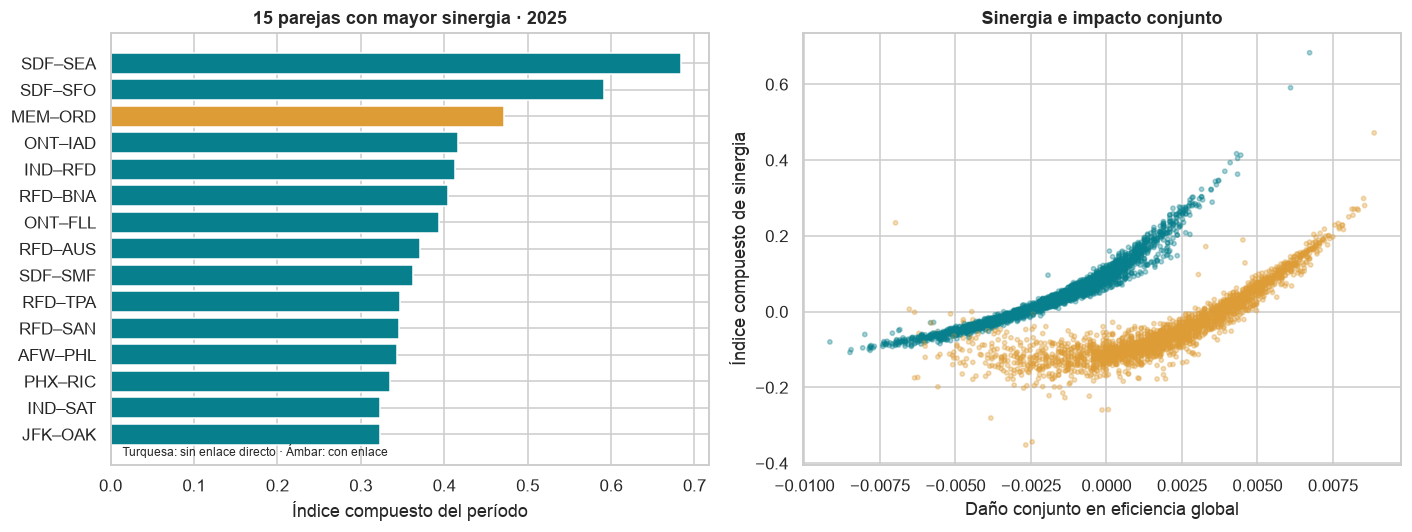

In [22]:
calibration = attach_results(networks, simulations, airports)
weights_table = pd.DataFrame({PERIODS[p]: n['composite']['weights'] for p, n in networks.items()},
                             index=['peso eficiencia global', 'peso eficiencia local', 'peso conectividad natural']).T
weights_table['suma'] = weights_table.sum(axis=1)
display(weights_table)
annual_pairs = networks['annual']['pairs'].sort_values(['score', 'a_id', 'b_id'], ascending=[False, True, True])
display(annual_pairs.head(20)[['rank', 'a', 'b', 'a_id', 'b_id', 'direct', 'score', 'synergy_global', 'synergy_local',
                               'synergy_natural', 'impact_global', 'impact_local', 'impact_natural']]
        .rename(columns={'rank': 'puesto', 'a_id': 'AirportID a', 'b_id': 'AirportID b', 'direct': 'enlace directo',
                         'score': 'índice', 'synergy_global': 'sinergia ef. global', 'synergy_local': 'sinergia ef. local',
                         'synergy_natural': 'sinergia conect. natural', 'impact_global': 'daño conjunto ef. global',
                         'impact_local': 'daño conjunto ef. local', 'impact_natural': 'daño conjunto conect. natural'}))
top10_pairs = annual_pairs.head(10)
display(Markdown(f"**Resultado:** {int((~top10_pairs.direct).sum())} de las diez parejas con mayor índice no tienen enlace directo. "
                 f"La primera es **{top10_pairs.iloc[0].a}–{top10_pairs.iloc[0].b}**, con índice **{top10_pairs.iloc[0].score:.4f}**. "
                 f"El índice anual va de **{annual_pairs.score.min():.3f}** a **{annual_pairs.score.max():.3f}**, y "
                 f"{int((annual_pairs.score < 0).sum()):,} de las 4.950 parejas tienen índice negativo."))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
shown = annual_pairs.head(15).iloc[::-1]
colors = np.where(shown.direct, '#dd9c36', '#087f8c')
axes[0].barh(shown.a+'–'+shown.b, shown.score, color=colors)
axes[0].set(title='15 parejas con mayor sinergia · 2025', xlabel='Índice compuesto del período')
axes[0].text(.02, .02, 'Turquesa: sin enlace directo · Ámbar: con enlace', transform=axes[0].transAxes, fontsize=8)
axes[1].scatter(annual_pairs.impact_global, annual_pairs.score, c=np.where(annual_pairs.direct, '#dd9c36', '#087f8c'), s=8, alpha=.35)
axes[1].set(title='Sinergia e impacto conjunto', xlabel='Daño conjunto en eficiencia global', ylabel='Índice compuesto de sinergia')
savefig('03_ranking_y_impacto.png')

**Interpretación.** La eficiencia local recibe el mayor peso (0,43 en el año) porque
sus sinergias se concentran en pocas parejas; la eficiencia global y la conectividad
natural pesan cerca de 0,27 y 0,30. La pareja con mayor sinergia anual es SDF–SEA,
sin conexión directa, y nueve de las diez primeras tampoco la tienen: el mismo
patrón que el artículo encontró en 2022. Una pareja sin enlace directo puede
sostener caminos alternativos en regiones distintas; al retirar ambos aeropuertos
desaparecen a la vez varias alternativas. El ranking describe esa interacción
estructural; por sí solo no identifica las rutas que absorberían la mercancía ni
demuestra que una pareja vaya a fallar simultáneamente.

### **7.3. Sinergia no es daño total**

El diagrama de dispersión muestra que el índice de sinergia y el daño conjunto en
eficiencia global se relacionan poco: la pareja que más daño total causa (MEM–ORD)
es la tercera en sinergia, y SDF–SEA, primera en sinergia, es la 56.ª en daño global.
**Mayor sinergia** responde a *¿qué parejas interactúan más allá de la suma?*;
**mayor daño** responde a *¿qué parejas duelen más al perderse?*. Las dos preguntas
se mantienen separadas en todo el notebook y en el explorador.

## **8. Qué explica la sinergia**

### **8.1. Variables de cada pareja**

Para explicar el índice se usan las seis variables que el artículo retiene tras su
filtro de colinealidad:

| Símbolo | Variable | Qué mide |
|---|---|---|
| X1 | Suma de carga | Carga incidente de los dos aeropuertos |
| X2 | Suma de grados | Qué tan conectados están, en conjunto |
| X3 | Diferencia de grado | Si son de tamaño parecido (0) o muy distinto |
| X4 | Diferencia de intermediación | Si cumplen papeles de puente parecidos o distintos |
| X5 | Distancia geográfica | Kilómetros de gran círculo entre ambos |
| D | Conexión directa | 1 si la pareja tiene enlace en la red, 0 si no |

`DISTANCE` de BTS solo informa millas de los segmentos con vuelo; para estudiar
**todas** las parejas, incluidas las que no tienen enlace, se calcula la distancia de
gran círculo con las coordenadas. La celda contrasta ambas medidas para detectar
errores de unidades o de ubicación y muestra las correlaciones entre variables.

In [23]:
predictors = pair_predictors(networks['annual'], airports)
geo_lookup = airports.set_index('airport_id')
check = inside_routes.copy()
check['great_circle_km'] = haversine_km(check.ORIGIN_AIRPORT_ID.map(geo_lookup.lat), check.ORIGIN_AIRPORT_ID.map(geo_lookup.lon),
                                        check.DEST_AIRPORT_ID.map(geo_lookup.lat), check.DEST_AIRPORT_ID.map(geo_lookup.lon))
check['bts_km'] = check.distance_miles*1.609344
check['diferencia_km'] = (check.bts_km-check.great_circle_km).abs()
display(check[['bts_km', 'great_circle_km', 'diferencia_km']].describe(percentiles=[.5, .95, .99]))
predictor_names = {'freight_sum': 'X1 suma de carga', 'degree_sum': 'X2 suma de grados', 'degree_diff': 'X3 diferencia de grado',
                   'betweenness_diff': 'X4 diferencia de intermediación', 'geo_distance_km': 'X5 distancia', 'direct': 'D conexión directa'}
display(predictors[list(predictor_names)].corr().rename(index=predictor_names, columns=predictor_names).round(3))

,bts_km,great_circle_km,diferencia_km
count,"36,262.00000","36,262.00000","36,262.00000"
mean,"1,741.14121","1,739.16367",2.99781
std,"1,267.01532","1,264.53126",2.67166
min,9.65606,8.92555,0.00050
50%,"1,414.61338","1,417.50853",2.20288
95%,"4,087.73376","4,082.88361",8.33931
99%,"6,057.57082","6,046.99531",11.21445
max,"8,199.60768","8,186.04436",14.97271


,X1 suma de carga,X2 suma de grados,X3 diferencia de grado,X4 diferencia de intermediación,X5 distancia,D conexión directa
X1 suma de carga,1.00000,0.45000,0.16100,0.48200,0.05100,0.27600
X2 suma de grados,0.45000,1.00000,0.04300,0.48900,-0.22300,0.61400
X3 diferencia de grado,0.16100,0.04300,1.00000,0.71300,0.02800,-0.02800
X4 diferencia de intermediación,0.48200,0.48900,0.71300,1.00000,-0.08800,0.30500
X5 distancia,0.05100,-0.22300,0.02800,-0.08800,1.00000,-0.33000
D conexión directa,0.27600,0.61400,-0.02800,0.30500,-0.33000,1.00000


**Interpretación.** La distancia de gran círculo y la de BTS difieren menos de 15 km
en todas las rutas: las coordenadas son coherentes. La suma de grados y la conexión
directa están correlacionadas (0,61): los aeropuertos muy conectados tienden a estar
conectados entre sí. La matriz es descriptiva; no incluye pruebas de independencia.

### **8.2. Regresión para datos de red (MRQAP)**

**Por qué una regresión especial.** Las 4.950 observaciones no son independientes:
cada aeropuerto aparece en 99 parejas. Una regresión ordinaria daría valores p
engañosos. **MRQAP** ajusta la regresión por mínimos cuadrados, pero obtiene la
referencia nula permutando a la vez filas y columnas de la matriz de respuesta, es
decir, barajando la identidad de los aeropuertos. Así la dependencia entre parejas
que comparten un aeropuerto se conserva bajo la hipótesis nula. Se usan 9.999
permutaciones, semilla 2025 y contraste bilateral.

**Los cinco modelos** tienen la misma especificación que el artículo y no se eligen
mirando los valores p de 2025. Las variables continuas se estandarizan (media 0,
desviación 1), así que cada coeficiente es el cambio del índice cuando la variable
sube una desviación típica.

| Modelo | Qué incluye | Pregunta que responde |
|---|---|---|
| M1 | X1 a X5 | ¿Cuánto explican volumen, centralidad y distancia, sin saber si la pareja está conectada? |
| M2 | Solo D | ¿Cuánto explica, por sí sola, la conexión directa? |
| M3 | X1 a X5 y D | ¿Cuánto explican juntas? |
| M4 | M3 más la interacción de cada variable con D | ¿El efecto de cada variable cambia si la pareja está conectada? |
| M5 | M4 reducido a los términos que retiene el artículo | Versión parsimoniosa de M4 |

R² mide el ajuste dentro de esta red: no es exactitud predictiva fuera de muestra
ni porcentaje de carga protegida, y los contrastes son exploratorios, sin corrección
por comparaciones múltiples.

,modelo,términos,R² 2025,p de permutación del R²,R² del artículo (2022)
0,M1,5,0.19165,0.00010,0.15320
1,M2,1,0.20206,0.00010,0.13870
2,M3,6,0.84574,0.00010,0.69050
3,M4,11,0.87274,0.00010,0.73940
4,M5,8,0.87223,0.00010,0.73910


,coeficiente,p de permutación
variable,,
constante,0.11219,0.00010
X2 suma de grados,0.11496,0.00010
X3 diferencia de grado,-0.01642,0.00070
X4 diferencia de intermediación,0.00598,0.24130
X5 distancia,0.00456,0.13060
D conexión directa,-0.20376,0.00010
X1 × D,0.00640,0.11910
X2 × D,-0.04284,0.00010
X3 × D,-0.01006,0.01690


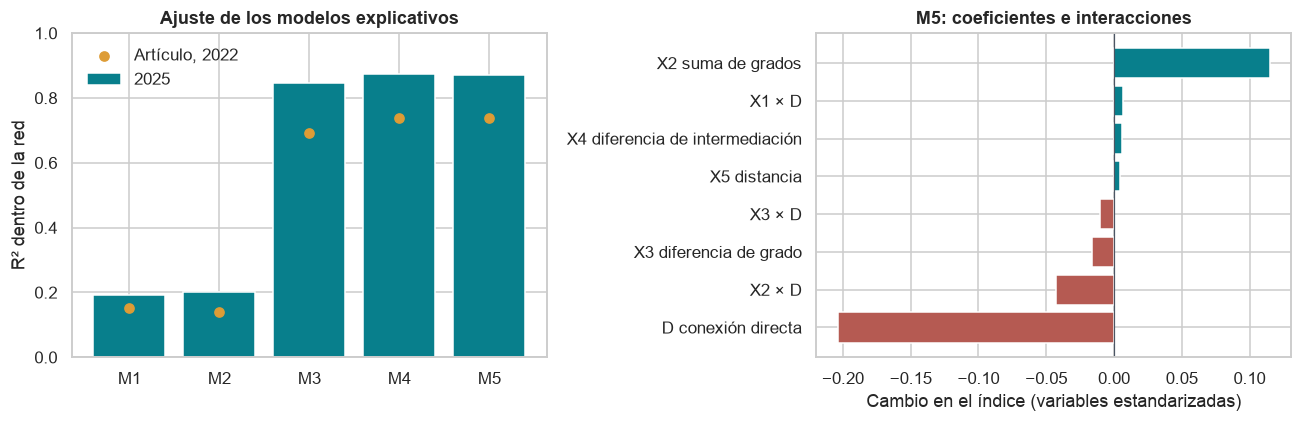

In [24]:
ARTICLE_R2 = {'M1': 0.1532, 'M2': 0.1387, 'M3': 0.6905, 'M4': 0.7394, 'M5': 0.7391}
if EJECUTAR_MRQAP:
    models, coefficients, standardization = mrqap_models(predictors, airports.airport_id,
                                                         permutations=N_PERMUTACIONES, seed=SEED)
    models_view = models[['model', 'predictors', 'r2', 'p_r2']].copy()
    models_view['R² del artículo (2022)'] = models_view.model.map(ARTICLE_R2)
    display(models_view.rename(columns={'model': 'modelo', 'predictors': 'términos', 'r2': 'R² 2025',
                                        'p_r2': 'p de permutación del R²'}))
    variable_names = {'intercept': 'constante', 'degree_sum': 'X2 suma de grados', 'degree_diff': 'X3 diferencia de grado',
                      'betweenness_diff': 'X4 diferencia de intermediación', 'geo_distance_km': 'X5 distancia',
                      'direct': 'D conexión directa', 'freight_sum×direct': 'X1 × D', 'degree_sum×direct': 'X2 × D',
                      'degree_diff×direct': 'X3 × D'}
    m5 = coefficients[coefficients.model.eq('M5')].copy()
    m5['variable'] = m5.variable.map(variable_names)
    display(m5[['variable', 'coefficient', 'p_permutation']].rename(
        columns={'coefficient': 'coeficiente', 'p_permutation': 'p de permutación'}).set_index('variable'))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].bar(models.model, models.r2, color='#087f8c', label='2025')
    axes[0].scatter(models.model, models.model.map(ARTICLE_R2), color='#dd9c36', zorder=3, label='Artículo, 2022')
    axes[0].set(title='Ajuste de los modelos explicativos', ylabel='R² dentro de la red', ylim=(0, 1))
    axes[0].legend(frameon=False)
    c = m5[m5.variable.ne('constante')].sort_values('coefficient')
    axes[1].barh(c.variable, c.coefficient, color=np.where(c.coefficient.ge(0), '#087f8c', '#b55a52'))
    axes[1].axvline(0, color='#4b5563', lw=.8)
    axes[1].set(title='M5: coeficientes e interacciones', xlabel='Cambio en el índice (variables estandarizadas)')
    savefig('06_modelos_mrqap.png')
    models.to_csv(OUT/'mrqap_modelos.csv', index=False)
    coefficients.to_csv(OUT/'mrqap_coeficientes.csv', index=False)
    write_json(OUT/'mrqap_estandarizacion.json', standardization)
else:
    print('MRQAP omitido por configuración; el análisis de robustez y la app siguen completos.')

**Interpretación.**

- **Complementariedad.** Por separado, las variables continuas (M1) y la conexión
  directa (M2) explican cerca de un 20 % cada una; juntas (M3) explican el 85 %. El
  efecto de la centralidad depende de si la pareja está conectada, y por eso las
  interacciones de M4 y M5 mejoran algo más el ajuste.
- **La conexión directa es el factor dominante:** una pareja conectada tiene un
  índice 0,20 menor. Es el mecanismo de la sección 6.1: el daño del enlace común
  se cuenta en los dos fallos individuales.
- **La suma de grados** aumenta el índice: 0,115 por desviación típica si la pareja
  no está conectada y 0,072 si lo está (0,115 − 0,043). Dos hubs sin enlace directo
  interactúan más. El artículo encuentra el mismo patrón (0,39 sin enlace y 0,18 con
  enlace).
- **La diferencia de grado** resta: parejas de tamaño parecido interactúan más.
- **La carga, la distancia y la diferencia de intermediación** no resultan
  significativas con esta permutación: la sinergia la explica la estructura, no el
  volumen.
- Los R² siguen el mismo orden que en el artículo y son algo mayores en 2025. Parte
  del ajuste es mecánico, porque el índice y los predictores se construyen sobre el
  mismo grafo: la regresión describe la red; no predice ni prueba causas.

### **8.3. Sensibilidad M6 del artículo**

El artículo revisa los residuos de M5 y, al ver curvatura frente a la suma de grados,
añade su cuadrado (**Model 6**). Lo presenta como análisis de sensibilidad, sin
reemplazar a M5. La celda reproduce ese ajuste con las mismas variables
estandarizadas; los valores p de M6 se revisan en la sección 9.6.

In [25]:
designs, _, _ = _designs(predictors)
fits = {name: _fit(x, predictors.score.to_numpy()) for name, (x, _) in designs.items()}
display(pd.DataFrame({'R²': {k: f['r2'] for k, f in fits.items()}, 'error cuadrático medio (RMSE)': {k: f['rmse'] for k, f in fits.items()}}))
m6_terms = designs['M6'][1]
print(f"Coeficiente del cuadrado de la suma de grados en M6: {fits['M6']['beta'][m6_terms.index('degree_sum_squared')]:.4f}")
if EJECUTAR_MRQAP:
    assert np.isclose(fits['M5']['r2'], models.set_index('model').loc['M5', 'r2'])

,R²,error cuadrático medio (RMSE)
M5,0.87223,0.03405
M6,0.95757,0.01962


Coeficiente del cuadrado de la suma de grados en M6: 0.0385


**Interpretación.** El R² pasa de 0,87 a 0,96 y el término cuadrático es positivo: la
sinergia crece más rápido que linealmente con la suma de grados, es decir, entre
parejas de hubs. Esto justifica estudiar la forma funcional, pero no demuestra
predicción fuera de muestra ni causalidad.

## **9. Firmeza de los resultados**

Un ranking calculado sobre una instantánea y una definición de red puede depender
de ambas. Esta sección, aporte propio del equipo, somete el resultado a seis
pruebas: cambiar de trimestre, cambiar la regla que define un enlace, contar qué
parejas permanecen bajo todas las reglas, mirar qué pasa con los caminos entre los
aeropuertos que sobreviven, retirar operadores enteros y recalcular los valores p
de la regresión con otro método de permutación.

**Cómo se comparan dos rankings: correlación de Spearman.** Spearman mide si dos
listas **ordenan igual** las mismas parejas. Convierte cada lista en puestos y
calcula la correlación entre puestos: 1 es el mismo orden, 0 sin relación y −1 el
orden inverso. Sin empates,

$$\rho = 1-\frac{6\sum_i d_i^2}{n(n^2-1)}$$

donde $d_i$ es la diferencia de puesto de la pareja $i$ en las dos listas y $n$ el
número de parejas; con empates se usa el puesto medio. Se usa en lugar de la
correlación de Pearson por tres razones: lo que interesa es el **orden de
prioridad**, no el valor del índice; los índices de trimestres o reglas distintas no
están en la misma escala; y es robusto a valores extremos. Su límite: con 4.950
parejas, un ρ alto puede convivir con cambios grandes en las primeras posiciones,
por eso siempre se acompaña de la **coincidencia del top 20**.

La celda siguiente ejecuta las ampliaciones (con cachés verificadas) y exporta sus
datos para la app.

In [26]:
N_PERMUTACIONES_SENSIBILIDAD = 1999
extensions = run_project_extensions(raw, clean, routes, airports, networks, simulations, ROOT,
                                    permutations=N_PERMUTACIONES_SENSIBILIDAD, seed=SEED, use_cache=USAR_CACHE)
print('Ampliaciones exportadas: resultados/ampliaciones/ y app/dist/data/extensions.json')

Ampliación estructural: annual / base


Ampliación estructural: annual / half_months


Ampliación estructural: annual / all_months


Ampliación estructural: annual / min_monthly_freight


Ampliación estructural: T1 / base


Ampliación estructural: T1 / half_months


... (12 outputs left out)

Ampliación estructural: T4 / all_months


Ampliación estructural: T4 / min_monthly_freight


Inferencia ampliada: caché de insumos, método y archivos verificada.


Ampliaciones exportadas: resultados/ampliaciones/ y app/dist/data/extensions.json


### **9.1. Variación entre trimestres**

Para comparar trimestres hace falta una regla de medida común: se mantienen los
pesos estimados en la red anual y se normaliza cada medida por su máximo absoluto
entre los cuatro trimestres (índice comparable). Esta calibración es retrospectiva,
no un modelo de predicción disponible al comienzo del año. Para cada par de
trimestres se calcula Spearman entre los índices de las 4.950 parejas, la
coincidencia del top 20 y los cambios de conexiones. Un año permite hablar de
**variación trimestral**, no de un patrón estacional recurrente.

,medida,peso anual,divisor común trimestral
0,eficiencia global,0.27144,0.00977
1,eficiencia local,0.42785,0.01069
2,conectividad natural,0.30071,0.06410


,trimestre A,trimestre B,Spearman (índice comparable),Spearman (índice propio),top,parejas comunes en el top,coincidencia del top,Jaccard del top,Jaccard de enlaces,enlaces comunes,enlaces perdidos,enlaces nuevos
0,T1,T2,0.75199,0.74973,20,5,0.25000,0.14286,0.79990,1643,175,236
1,T1,T3,0.69819,0.68834,20,6,0.30000,0.17647,0.76264,1629,189,318
2,T1,T4,0.73812,0.72111,20,9,0.45000,0.29032,0.76973,1658,160,336
3,T2,T3,0.73664,0.72912,20,6,0.30000,0.17647,0.79540,1695,184,252
4,T2,T4,0.70616,0.69714,20,6,0.30000,0.17647,0.75886,1671,208,323
5,T3,T4,0.71285,0.71082,20,11,0.55000,0.37931,0.77044,1715,232,279


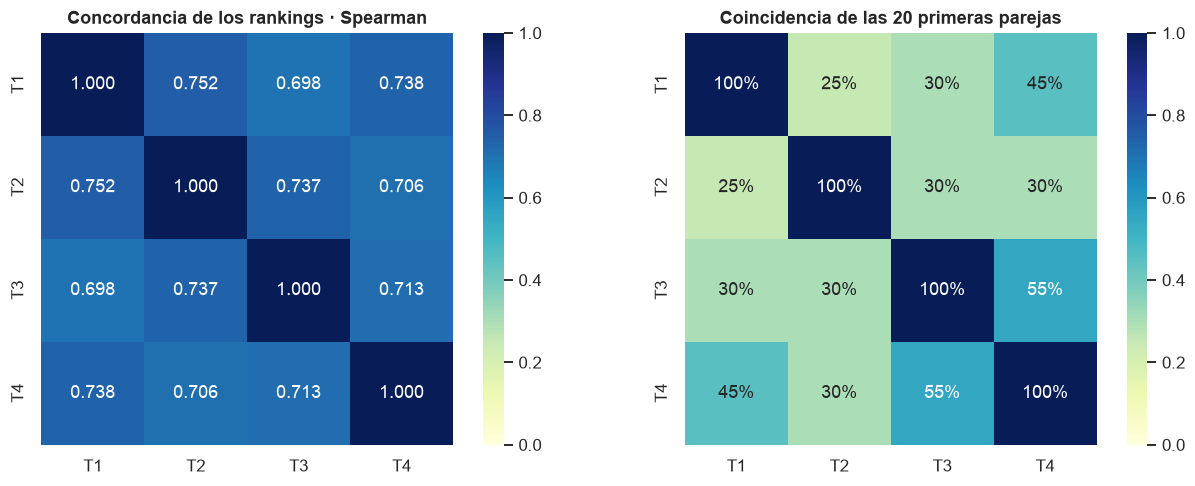

In [27]:
comparison, trajectories = compare_quarters(networks)
display(pd.DataFrame({'medida': ['eficiencia global', 'eficiencia local', 'conectividad natural'],
                      'peso anual': calibration['weights_from_annual'],
                      'divisor común trimestral': calibration['scales_from_quarters']}))
display(comparison.rename(columns={'period_a': 'trimestre A', 'period_b': 'trimestre B', 'spearman': 'Spearman (índice comparable)',
                                   'spearman_period_specific': 'Spearman (índice propio)', 'top_k': 'top', 'shared_top': 'parejas comunes en el top',
                                   'overlap': 'coincidencia del top', 'top_jaccard': 'Jaccard del top', 'edge_jaccard': 'Jaccard de enlaces',
                                   'edges_common': 'enlaces comunes', 'edges_lost': 'enlaces perdidos', 'edges_added': 'enlaces nuevos'}))
qs = ['T1', 'T2', 'T3', 'T4']
rho = pd.DataFrame(np.eye(4), index=qs, columns=qs); overlap = rho.copy()
for row in comparison.itertuples():
    rho.loc[row.period_a, row.period_b] = rho.loc[row.period_b, row.period_a] = row.spearman
    overlap.loc[row.period_a, row.period_b] = overlap.loc[row.period_b, row.period_a] = row.overlap
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(rho, annot=True, fmt='.3f', vmin=0, vmax=1, cmap='YlGnBu', ax=axes[0], square=True)
axes[0].set_title('Concordancia de los rankings · Spearman')
sns.heatmap(overlap, annot=True, fmt='.0%', vmin=0, vmax=1, cmap='YlGnBu', ax=axes[1], square=True)
axes[1].set_title('Coincidencia de las 20 primeras parejas')
savefig('04_comparacion_trimestral.png')

**Interpretación.** La correlación entre rankings trimestrales es moderada-alta (0,70
a 0,75), pero el top 20 coincide mucho menos (25 % a 55 %): la concordancia de
conjunto convive con cambios importantes en las primeras posiciones.

La figura siguiente sigue la posición de seis parejas que están en el top 20 de
varios trimestres. El eje vertical es logarítmico para que se vean a la vez los
primeros puestos y las caídas. Los trimestres en los que la pareja tiene **enlace
directo** se marcan con una cruz.

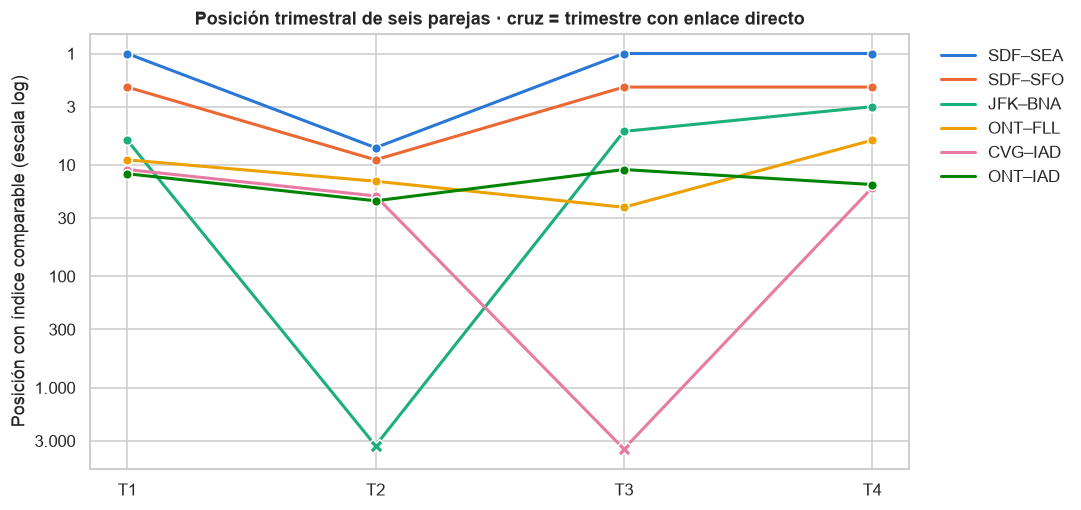

,pareja,trimestre,puesto,enlace directo,meses con vuelo,carga del enlace (lb),salidas
0,JFK–BNA,T2,3315,True,4,"17,724.00000",1
1,CVG–IAD,T3,3548,True,7,437.00000,1


Caídas por debajo del puesto 3.000 de parejas que están en algún top 20 trimestral: 64; con enlace directo en ese trimestre: 64.


In [28]:
pairs_by_quarter = {q: networks[q]['pairs'].set_index('pair_key') for q in qs}
chosen = trajectories.sort_values(['top20_quarters', 'T1_rank'], ascending=[False, True]).head(6)
LINE_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
fig, ax = plt.subplots(figsize=(10, 4.8))
for color, row in zip(LINE_COLORS, chosen.to_dict(orient='records')):
    ranks_q = [row[f'{q}_rank'] for q in qs]
    direct_q = [bool(pairs_by_quarter[q].loc[row['pair_key'], 'direct']) for q in qs]
    ax.plot(qs, ranks_q, color=color, lw=2, label=row['a']+'–'+row['b'])
    for q, r, d in zip(qs, ranks_q, direct_q):
        ax.scatter(q, r, color=color, s=80 if d else 40, marker='X' if d else 'o', edgecolor='white', zorder=3)
ax.set_yscale('log'); ax.invert_yaxis()
ticks = [1, 3, 10, 30, 100, 300, 1000, 3000]
ax.set_yticks(ticks); ax.set_yticklabels([f'{t:,}'.replace(',', '.') for t in ticks]); ax.minorticks_off()
ax.set(title='Posición trimestral de seis parejas · cruz = trimestre con enlace directo',
       ylabel='Posición con índice comparable (escala log)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
savefig('05_trayectorias_ranking.png')
drops = []
for row in chosen.itertuples():
    for q_index, q in enumerate(qs, start=1):
        if getattr(row, f'{q}_rank') > 3000:
            link = monthly_link(row.a, row.b, quarter=q_index)
            drops.append({'pareja': f'{row.a}–{row.b}', 'trimestre': q, 'puesto': int(getattr(row, f'{q}_rank')),
                          'enlace directo': bool(pairs_by_quarter[q].loc[row.pair_key, 'direct']),
                          'meses con vuelo': ', '.join(map(str, link.mes)), 'carga del enlace (lb)': link.carga_lb.sum(),
                          'salidas': int(link.salidas.sum())})
display(pd.DataFrame(drops))
falls = [(q, pk) for q in qs for pk in trajectories.loc[(trajectories.top20_quarters >= 1) & (trajectories[f'{q}_rank'] > 3000), 'pair_key']]
print(f'Caídas por debajo del puesto 3.000 de parejas que están en algún top 20 trimestral: {len(falls)}; '
      f'con enlace directo en ese trimestre: {sum(bool(pairs_by_quarter[q].loc[pk, "direct"]) for q, pk in falls)}.')

**Interpretación.** Los saltos cerca del puesto 3.500 no se deben a que un
aeropuerto desaparezca: los 100 aeropuertos son los mismos en todos los trimestres.
Se deben a que **en ese trimestre la pareja tiene un enlace directo**, a menudo de un
solo vuelo: JFK–BNA cae en T2 por un vuelo en abril y CVG–IAD cae en T3 por un vuelo
de 437 lb en julio. En todos los casos en que una pareja del top 20 de algún
trimestre cae por debajo del puesto 3.000, ese trimestre tiene enlace directo.

El puesto concreto, cerca de 3.500, también tiene explicación. En cada trimestre
hay entre 1.800 y 2.000 parejas conectadas, y casi todas ocupan el final del
ranking. Ganar un enlace directo mueve a la pareja del bloque de no conectadas al
bloque de conectadas, por el mecanismo de la sección 6.1.

Solo SDF–SEA y SDF–SFO permanecen en el top 20 de los cuatro trimestres.

### **9.2. Sensibilidad a la regla de enlace**

La regla base crea un enlace ante cualquier carga positiva. Se comparan tres reglas
alternativas, predefinidas y no elegidas para obtener un resultado: conexión
presente en al menos la mitad de los meses del período, presente en todos los
meses, y carga promedio de al menos 1.000 lb por mes calendario. Son 20 redes
(cuatro reglas × cinco períodos) sobre los mismos 100 aeropuertos.

**Sobre qué se calcula Spearman aquí.** Para cada período se compara el índice de
las 4.950 parejas con la regla alternativa contra el índice con la regla base del
mismo período. Para que los índices sean comparables, todas las redes usan una
escala por medida común a todas las reglas y períodos (calibración común de
sensibilidad) y los pesos de la red anual base. Por eso la fila de la regla base da
ρ = 1: es la base comparada consigo misma. Estos índices no se mezclan con los del
ranking principal ni con la calibración trimestral.

In [29]:
sensitivity_summary = pd.read_csv(OUT/'ampliaciones/resumen_sensibilidad.csv')
display(sensitivity_summary[['period', 'variant', 'n_edges', 'components', 'freight_coverage', 'spearman', 'shared_top']]
        .rename(columns={'period': 'período', 'variant': 'regla', 'n_edges': 'enlaces', 'components': 'componentes',
                         'freight_coverage': 'carga interna conservada', 'spearman': 'Spearman con la base',
                         'shared_top': 'parejas comunes en el top 20'}))
cases_sensitivity = pd.read_csv(OUT/'ampliaciones/casos_sensibilidad.csv')
display(cases_sensitivity[cases_sensitivity['case'].isin(['ONT–STL', 'CVG–IAD']) & cases_sensitivity.period.eq('annual')]
        [['variant', 'case', 'direct', 'rank', 'score_comparable']]
        .rename(columns={'variant': 'regla', 'case': 'pareja', 'direct': 'enlace directo',
                         'rank': 'puesto (calibración común de sensibilidad)', 'score_comparable': 'índice'}))
for a, b in [('ONT', 'STL'), ('CVG', 'IAD')]:
    print(f'Vuelos {a}–{b} en 2025 (ambos sentidos):')
    display(monthly_link(a, b))

,período,regla,enlaces,componentes,carga interna conservada,Spearman con la base,parejas comunes en el top 20
0,annual,base,2441,1,1.00000,1.00000,20
1,annual,half_months,1619,1,0.99489,0.54342,3
2,annual,all_months,1337,1,0.97268,0.38285,2
3,annual,min_monthly_freight,1939,1,0.99994,0.70336,12
4,T1,base,1818,1,1.00000,1.00000,20
5,T1,half_months,1574,1,0.99852,0.84275,8
6,T1,all_months,1458,1,0.99481,0.77426,9
7,T1,min_monthly_freight,1578,1,0.99997,0.81544,10
8,T2,base,1879,1,1.00000,1.00000,20
9,T2,half_months,1607,1,0.99911,0.81934,6


,regla,pareja,enlace directo,puesto (calibración común de sensibilidad),índice
2,base,ONT–STL,True,"3,005.00000",-0.00475
3,base,CVG–IAD,True,"2,907.00000",-0.00283
6,half_months,ONT–STL,False,13.00000,0.12986
7,half_months,CVG–IAD,False,20.00000,0.11381
10,all_months,ONT–STL,False,26.00000,0.11658
11,all_months,CVG–IAD,False,132.00000,0.06428
14,min_monthly_freight,ONT–STL,False,5.00000,0.15561
15,min_monthly_freight,CVG–IAD,False,16.00000,0.11798


Vuelos ONT–STL en 2025 (ambos sentidos):


,trimestre,mes,sentidos,carga_lb,salidas
0,2,6,1,16.00000,1.00000


Vuelos CVG–IAD en 2025 (ambos sentidos):


,trimestre,mes,sentidos,carga_lb,salidas
0,3,7,1,437.00000,1.00000


**Interpretación.** Exigir presencia en todos los meses conserva más del 97 % de la
carga interna, pero comparte solo dos de las veinte prioridades con la base y su
Spearman cae por debajo de 0,4: **el volumen retenido no garantiza estabilidad del
ranking**.

Los casos ONT–STL y CVG–IAD muestran el mecanismo con datos. En la red anual base,
ONT–STL tiene enlace directo por **un único vuelo en junio con 16 lb**, y queda en el
puesto 3.005 con índice ligeramente negativo. Con cualquier regla que exija
persistencia o volumen, ese enlace desaparece y la pareja sube a los puestos 5 a 26.
CVG–IAD hace lo mismo por un vuelo de 437 lb en julio. Que una pareja quede o no
conectada por un vuelo mínimo decide su posición, porque la conexión directa es el
factor que más pesa en la sinergia (sección 8.2).

### **9.3. Parejas que permanecen bajo las cuatro reglas**

Para cada regla se seleccionan exactamente veinte parejas por índice comparable y
se cuenta en cuántas reglas aparece cada pareja (0/4 a 4/4). Es un recuento de
presencia entre estas cuatro definiciones: no es probabilidad de fallo ni intervalo
de confianza. Después se repite la caracterización estructural de la sección 4.2
para las quince redes alternativas, para ver si exigir persistencia o volumen
cambia el tipo de red.

,a,b,reglas con la pareja en el top 20,mejor puesto,peor puesto,puesto medio,base,mitad de meses,todos los meses,volumen mínimo
114,SDF,SEA,4,1.00000,3.00000,1.50000,1.00000,1.00000,3.00000,1.00000
121,SDF,SFO,4,2.00000,5.00000,2.75000,2.00000,2.00000,5.00000,2.00000
798,ONT,FLL,3,4.00000,39.00000,17.25000,4.00000,15.00000,39.00000,11.00000
1733,PHX,FLL,3,4.00000,"1,335.00000",339.25000,"1,335.00000",4.00000,10.00000,8.00000
1252,RFD,BNA,2,4.00000,79.00000,29.00000,5.00000,28.00000,79.00000,4.00000
1230,RFD,AUS,2,6.00000,80.00000,32.00000,7.00000,35.00000,80.00000,6.00000
585,IND,RFD,2,3.00000,93.00000,34.75000,6.00000,37.00000,93.00000,3.00000
799,ONT,IAD,2,3.00000,108.00000,37.50000,3.00000,24.00000,108.00000,15.00000
803,ONT,RDU,2,16.00000,78.00000,39.50000,16.00000,45.00000,78.00000,19.00000
1241,RFD,TPA,2,7.00000,104.00000,40.25000,8.00000,42.00000,104.00000,7.00000


Parejas anuales en el top 20 de las cuatro reglas: SDF–SEA, SDF–SFO


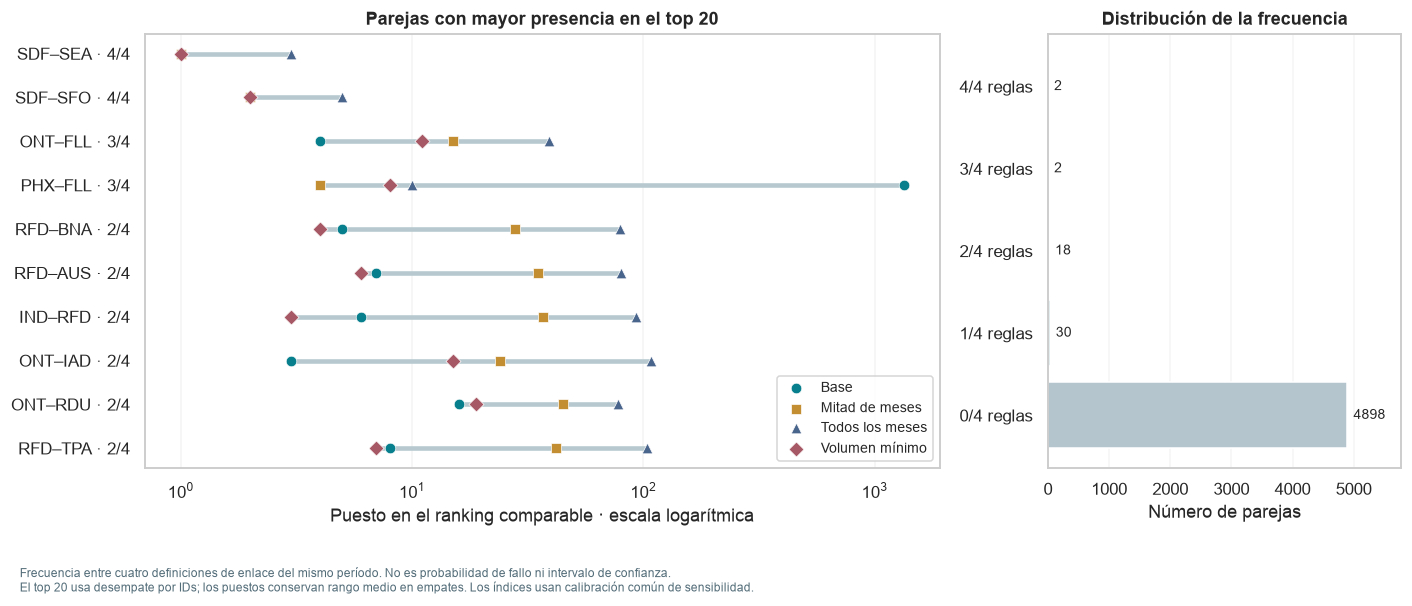

In [30]:
interactive = export_explorer(ROOT)
stability_annual = pd.read_csv(OUT/'ampliaciones/estabilidad_parejas_annual.csv')
stability_sorted = stability_annual.sort_values(['top_count', 'rank_mean', 'a_id', 'b_id'], ascending=[False, True, True, True])
rank_columns = [variant+'_rank' for variant in VARIANT_ORDER]
display(stability_sorted.head(20)[['a', 'b', 'top_count', 'rank_min', 'rank_max', 'rank_mean']+rank_columns]
        .rename(columns={'top_count': 'reglas con la pareja en el top 20', 'rank_min': 'mejor puesto', 'rank_max': 'peor puesto',
                         'rank_mean': 'puesto medio', 'base_rank': 'base', 'half_months_rank': 'mitad de meses',
                         'all_months_rank': 'todos los meses', 'min_monthly_freight_rank': 'volumen mínimo'}))
stable_every_rule = stability_sorted[stability_sorted.top_count.eq(len(VARIANT_ORDER))]
print('Parejas anuales en el top 20 de las cuatro reglas:', ', '.join(r.a+'–'+r.b for r in stable_every_rule.itertuples()))
stability_plot_data = plot_stability_ranges(stability_annual, FIG/'15_estabilidad_parejas.png', top_n=10)

In [31]:
exploration_variants = explore_variant_networks(airports, OUT/'ampliaciones', EXPLORACION, VARIANT_ORDER, list(PERIODS),
                                                runs=20, replicas=30, seed=SEED)
exploration_all = {**exploration_base, **exploration_variants}
exploration_payload = export_exploration(exploration_all, airports, ROOT/'app/dist/data/exploration.json', labels=VARIANTS)
(EXPLORACION/'exploracion.json').write_bytes((ROOT/'app/dist/data/exploration.json').read_bytes())
variant_rows = []
for (period, variant), result in exploration_all.items():
    s, c, m = result['summary'], result['communities'], result['models']
    variant_rows.append({'period': period, 'variant': variant, 'enlaces': s['n_edges'], 'densidad': s['density'],
                         'agrupamiento medio': s['average_clustering'], 'asortatividad': s['degree_assortativity'],
                         'distancia media': s['average_path_length'], 'núcleo k': s['max_core'],
                         'modularidad Q': c['modularity'], 'comunidades': c['n_communities'],
                         'perfil del curso': m['course_match'], 'modelo más cercano': m['closest_model']})
variant_structure = pd.DataFrame(variant_rows).sort_values(['period', 'variant'])
variant_structure.to_csv(EXPLORACION/'resumen_estructura_variantes.csv', index=False)
display(variant_structure[variant_structure.period.eq('annual')].set_index('variant').drop(columns='period'))
print('Bloques exportados para la app:', sum(len(v) for v in exploration_payload['networks'].values()))

,enlaces,densidad,agrupamiento medio,asortatividad,distancia media,núcleo k,modularidad Q,comunidades,perfil del curso,modelo más cercano
variant,,,,,,,,,,
all_months,1337,0.27010,0.71349,-0.32933,1.77111,27,0.14952,4,barabasi_albert,barabasi_albert
base,2441,0.49313,0.74564,-0.16105,1.50828,36,0.12148,3,barabasi_albert,barabasi_albert
half_months,1619,0.32707,0.75637,-0.29083,1.70000,30,0.14962,4,barabasi_albert,barabasi_albert
min_monthly_freight,1939,0.39172,0.71300,-0.16818,1.61535,33,0.14589,3,barabasi_albert,barabasi_albert


Bloques exportados para la app: 20


**Interpretación.** Solo SDF–SEA y SDF–SFO están en el top 20 anual bajo las cuatro
reglas (puestos 1/1/3/1 y 2/2/5/2). Existe, por tanto, un núcleo pequeño de parejas
persistentes dentro de un ranking globalmente inestable. En cuanto a la estructura,
retirar conexiones ocasionales reduce la densidad y acentúa el patrón
*hub-and-spoke* (asortatividad más negativa), sin cambiar el tipo de red: todas las
variantes conservan el perfil preferencial.

### **9.4. Caminos entre los aeropuertos supervivientes**

Una caída de la eficiencia promedio no implica necesariamente que los caminos se
hayan alargado: al retirar dos aeropuertos cambia también la población de parejas
sobre la que se promedia. Para separar ambos efectos se comparan **las mismas 98
× 97 / 2 = 4.753 parejas supervivientes** antes y después del fallo. Con
$E^{98}_{antes}$, la eficiencia entre los 98 supervivientes calculada con las
distancias de antes del fallo, el daño en eficiencia global se descompone
exactamente así:

$$\underbrace{E(G)-E(G\setminus\{i,j\})}_{\text{daño}}=\underbrace{E(G)-E^{98}_{antes}}_{\text{composición}}+\underbrace{E^{98}_{antes}-E^{98}_{después}}_{\text{distancias}}$$

El término de **composición** solo refleja que el promedio se calcula ahora sobre
otras parejas; el de **distancias** son los caminos que se alargaron o se rompieron.

La primera tabla aplica la descomposición a cuatro parejas de referencia. Sus
columnas son: el puesto en el índice anual (calibración propia del año, la del
ranking de 7.2), el puesto según el daño conjunto en eficiencia global, cuántas de
las 4.753 parejas supervivientes alargan su camino mínimo y los dos términos de la
fórmula.

In [32]:
case_rows = []
for case in extensions['interpretation']['cases']:
    case_rows.append({'pareja': case['a']+'–'+case['b'], 'puesto en el índice anual': case['rank'],
                      'puesto por daño global': case['joint_global_rank'],
                      'parejas supervivientes con camino más largo': case['paths']['worsened_pairs'],
                      'composición': case['paths']['composition_component'],
                      'distancias': case['paths']['path_component']})
display(pd.DataFrame(case_rows).set_index('pareja'))

,puesto en el índice anual,puesto por daño global,parejas supervivientes con camino más largo,composición,distancias
pareja,,,,,
SDF–SEA,1.00000,56.50000,0,0.00673,0.00000
MEM–ORD,3.00000,1.00000,13,0.00841,0.00046
ONT–STL,"1,592.00000",388.00000,3,0.00462,0.00011
CVG–IAD,"1,770.00000",561.00000,4,0.00399,0.00014


La segunda tabla muestra cómo se forma el índice de la primera pareja, SDF–SEA,
medida por medida: valor de la red antes del fallo, daño de cada aeropuerto por
separado, daño conjunto, sinergia, sinergia normalizada, peso y aporte al índice
(normalizada × peso). Los tres aportes suman el índice.

In [33]:
decomposition = pd.DataFrame(extensions['interpretation']['cases'][0]['metrics']).set_index('name')
decomposition.index = ['eficiencia global', 'eficiencia local', 'conectividad natural']
decomposition.columns = ['antes del fallo', 'daño de SDF', 'daño de SEA', 'daño conjunto', 'sinergia',
                         'sinergia normalizada', 'peso', 'aporte al índice']
display(decomposition)
print(f"Suma de aportes = índice de SDF–SEA: {decomposition['aporte al índice'].sum():.4f}")

,antes del fallo,daño de SDF,daño de SEA,daño conjunto,sinergia,sinergia normalizada,peso,aporte al índice
eficiencia global,0.74633,0.00394,0.00260,0.00673,0.00019,0.56066,0.27144,0.15218
eficiencia local,0.87280,0.00276,0.00121,0.00448,0.00051,0.53903,0.42785,0.23063
conectividad natural,52.72956,1.25613,1.04524,2.35015,0.04878,1.00000,0.30071,0.30071


Suma de aportes = índice de SDF–SEA: 0.6835


La tercera tabla es una sensibilidad: en lugar de retirar los dos aeropuertos, se
conservan los 100 nodos y se aíslan los fallidos, de modo que el denominador no
cambia. Muestra el Spearman y las parejas comunes del top 20 con el ranking base, y
cuántos impactos negativos en eficiencia global hay en cada versión.

In [34]:
fixed = extensions['interpretation']['fixed_universe']
display(pd.Series({'Spearman con el ranking base': fixed['spearman'], 'parejas comunes en el top 20': fixed['shared_top'],
                   'impactos globales negativos (base)': fixed['negative_global_impacts_base'],
                   'impactos globales negativos (universo fijo)': fixed['negative_global_impacts_fixed']}, name='valor').to_frame())

,valor
Spearman con el ranking base,0.85478
parejas comunes en el top 20,17.00000
impactos globales negativos (base),"2,473.00000"
impactos globales negativos (universo fijo),0.00000


**Interpretación.** En SDF–SEA ninguna de las 4.753 parejas supervivientes alarga su
camino mínimo: todo su daño global es composición, y lo que la red pierde es
redundancia (conectividad natural, que aporta casi la mitad de su índice). En
MEM–ORD sí se alargan trece caminos. El universo fijo conserva el ranking (Spearman
0,85; 17 de las 20 prioridades) y elimina los 2.473 impactos negativos, que eran un
efecto del denominador. Los puestos de esta sección usan la calibración propia del
año; los de la sección 9.2 usan la calibración común de sensibilidad, por eso
ONT–STL aparece aquí en el puesto 1.592 y allí en el 3.005.

### **9.5. Fallo de un operador completo**

Se construyen capas anuales de los ocho operadores con mayor carga interna. Al
retirar una compañía, una conexión permanece si otra compañía transportó carga en
ella. Es un contrafactual estructural: el volumen atribuido no estima pérdidas
reales ni redistribución, y los nombres identifican operadores, no clientes.

In [35]:
operator_rows = []
for operator in extensions['structural']['operators']['items']:
    operator_rows.append({'operador': operator['name'], 'cuota de la carga interna': operator['share'],
                          'enlaces de su capa': operator['layer']['stats']['n_edges'],
                          'enlaces que nadie más cubre': operator['removal']['edges_lost'],
                          'componentes sin el operador': operator['removal']['stats']['components'],
                          'daño en eficiencia global': operator['removal']['metrics_impact']['global_efficiency']})
display(pd.DataFrame(operator_rows))

,operador,cuota de la carga interna,enlaces de su capa,enlaces que nadie más cubre,componentes sin el operador,daño en eficiencia global
0,Federal Express Corporation,0.30017,508,125,1,0.01320
1,United Parcel Service,0.27214,803,261,1,0.02785
2,Air Transport International,0.09316,215,45,1,0.00461
3,Atlas Air Inc.,0.05533,190,10,1,0.00108
4,ABX Air Inc,0.04942,122,3,1,0.00034
5,Kalitta Air LLC,0.03038,50,1,1,0.00010
6,Hawaiian Airlines Inc.,0.01974,72,1,1,0.00010
7,Korean Air Lines Co. Ltd.,0.01941,18,0,1,0.00000


**Interpretación.** Sin UPS la red pierde 261 conexiones que ningún otro operador
cubre; sin FedEx, 125. Ambas redes restantes siguen conexas: los caminos agregados
existen, aunque mezclen compañías sin acuerdos de transferencia conocidos.

### **9.6. Valores p con otro método de permutación**

La sección 8.2 obtiene los valores p permutando la respuesta (las filas y columnas
de la matriz del índice). Una alternativa recomendada cuando hay colinealidad es
**Freedman–Lane**: ajustar el modelo sin el término que se prueba, permutar por
aeropuertos los residuos de ese ajuste, sumarlos al ajuste reducido y comparar el
estadístico t del modelo completo (1.999 permutaciones, semilla 2025, p mínimo
0,0005). Los dos procedimientos no contrastan exactamente la misma hipótesis; la
comparación es una **sensibilidad metodológica exploratoria**, sin corrección por
multiplicidad
([Dekker, Krackhardt y Snijders, 2007](https://www.stats.ox.ac.uk/~snijders/DekkerKrackhardtSnijders.pdf)).

In [36]:
inference_models = {m['model']: m for m in extensions['inference']['models']}
m5_inference = pd.DataFrame(inference_models['M5']['coefficients'])
m5_inference['term'] = m5_inference.term.map(variable_names)
display(m5_inference[['term', 'coefficient', 'p_baseline_Y', 'p_sensitivity']].set_index('term')
        .rename(columns={'coefficient': 'coeficiente', 'p_baseline_Y': 'p · permutación de la respuesta (8.2)',
                         'p_sensitivity': 'p · Freedman–Lane'}))
assert np.isclose(inference_models['M6']['r2'], fits['M6']['r2'])
m6_p = pd.DataFrame(inference_models['M6']['coefficients']).dropna(subset=['p_sensitivity'])
weak = [variable_names.get(t, t) for t in m6_p.loc[m6_p.p_sensitivity > 0.05, 'term']]
print(f"M6 (sección 8.3): R² = {inference_models['M6']['r2']:.4f}; términos con p de Freedman–Lane > 0,05: {', '.join(weak) or 'ninguno'}.")

,coeficiente,p · permutación de la respuesta (8.2),p · Freedman–Lane
term,,,
constante,0.11219,NaN,NaN
X2 suma de grados,0.11496,0.00010,0.00050
X3 diferencia de grado,-0.01642,0.00070,0.00050
X4 diferencia de intermediación,0.00598,0.24130,0.01300
X5 distancia,0.00456,0.13060,0.00250
D conexión directa,-0.20376,0.00010,0.00050
X1 × D,0.00640,0.11910,0.00200
X2 × D,-0.04284,0.00010,0.00050
X3 × D,-0.01006,0.01690,0.00050


M6 (sección 8.3): R² = 0.9576; términos con p de Freedman–Lane > 0,05: X1 × D.


**Interpretación.** Las conclusiones principales no cambian: la conexión directa, la
suma de grados, la diferencia de grado y sus interacciones son significativas con
ambos métodos. Cambian los predictores débiles: la diferencia de intermediación (p
de 0,24 a 0,013) y la distancia (p de 0,13 a 0,003) pasan a ser significativas con
Freedman–Lane. La significación de esos efectos pequeños depende del método de
permutación, y no conviene apoyar conclusiones en ellos.

## **10. Exportación de resultados y explorador**

Se guardan tablas completas, parámetros, huellas, versiones y los JSON del
explorador *Atlas Cargo*. El mapa consume **exactamente estos resultados**, no cifras
escritas a mano. Cada pareja incluye sinergia, impacto conjunto e impactos
individuales, lo que permite reconstruir las medidas después de los fallos y
reproducir el cálculo paso a paso en la ficha de la app.

**Dónde está la app.** Archivo autónomo: [`Atlas_Carga_Aerea_2025.html`](Atlas_Carga_Aerea_2025.html)
(doble clic; no necesita servidor). Versión de desarrollo en `app/dist/`, que se
sirve con `python -m http.server 8765 --directory app/dist` y se abre en
`http://localhost:8765`. Tras modificar la app, `python src/empaquetar_app.py`
reconstruye el archivo autónomo con los JSON recién exportados. No hay despliegue
público; el ZIP de entrega incluye el HTML.

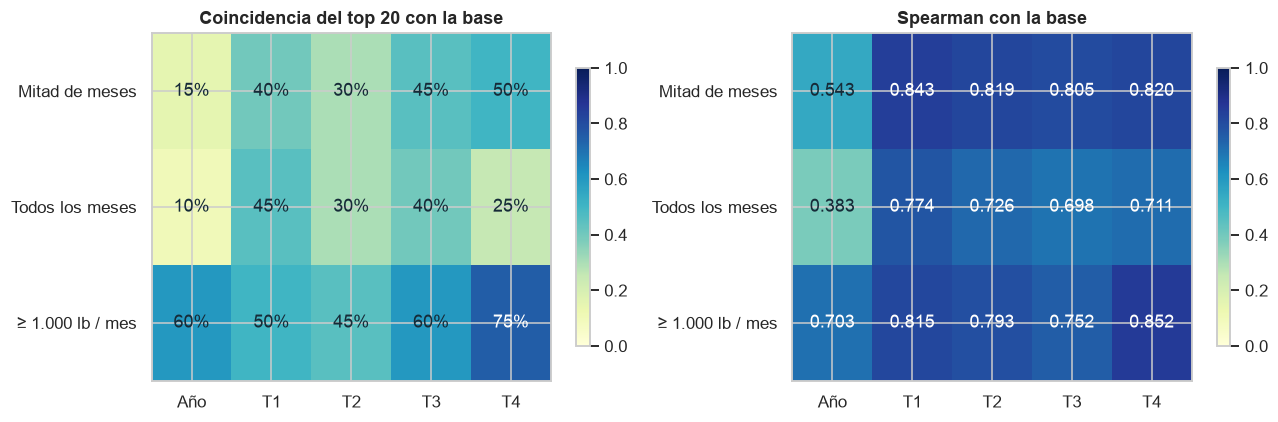

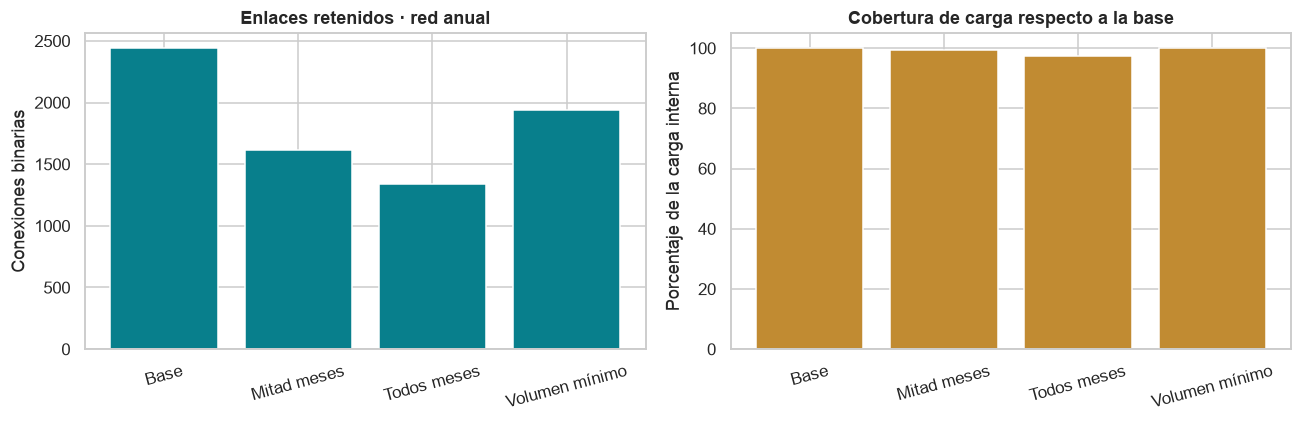

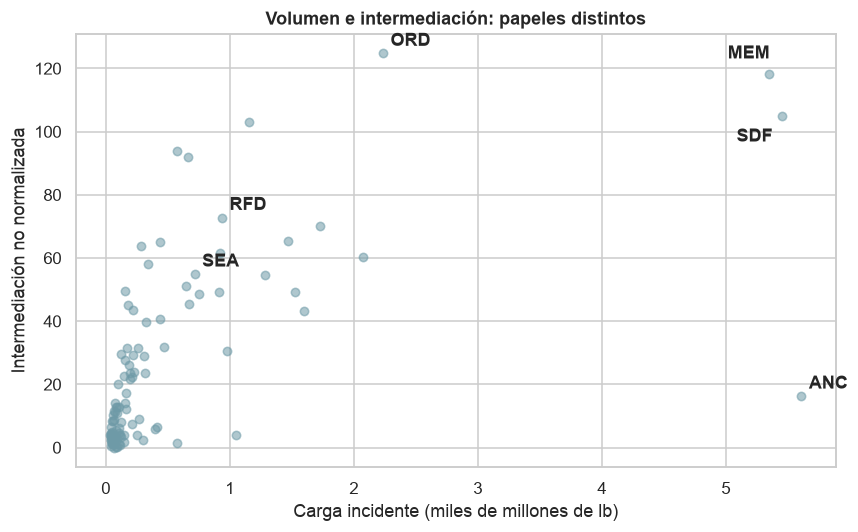

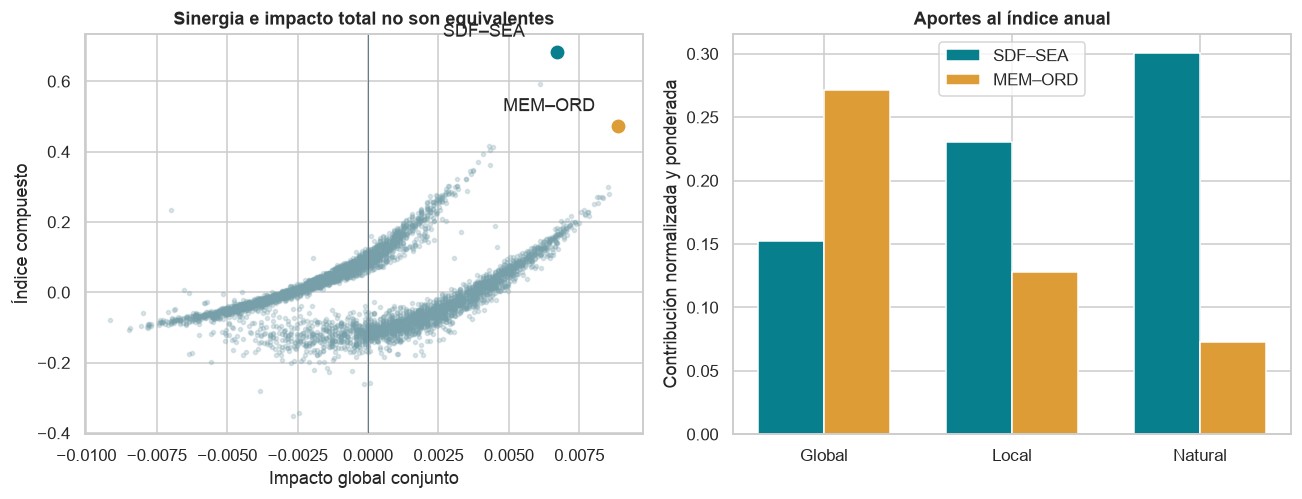

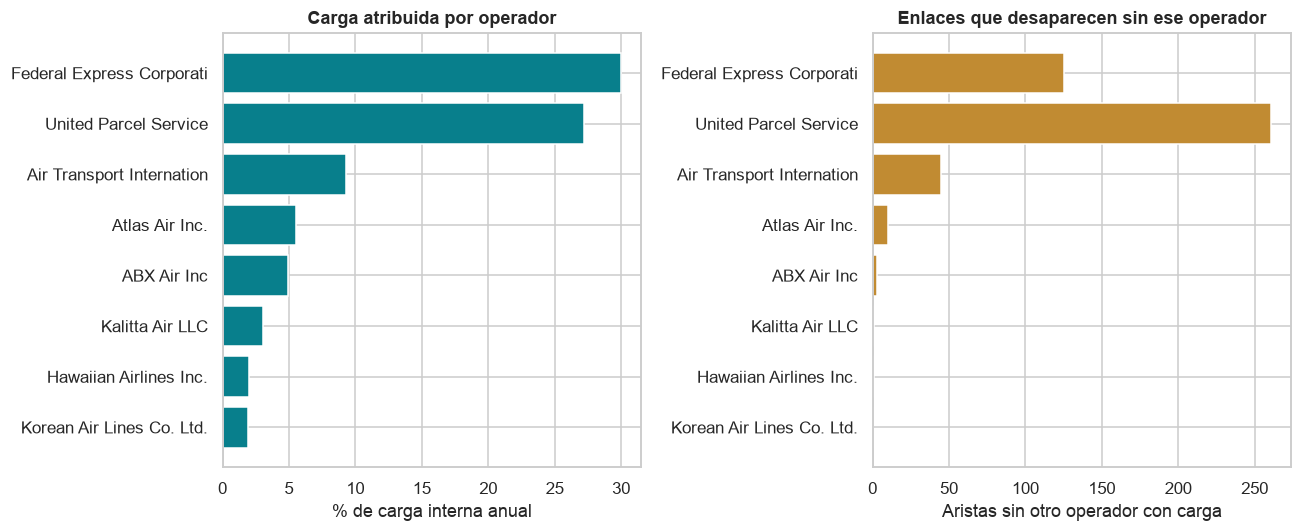

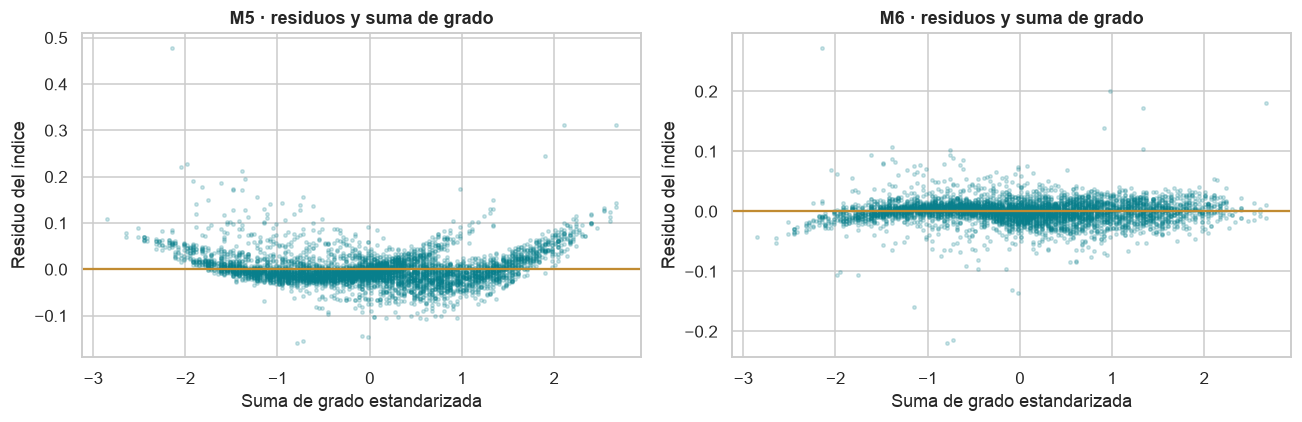

Resultados: resultados
Figuras: figuras | figuras de las ampliaciones: 6
App: exportadas 24750 parejas-período.


In [37]:
for p, n in networks.items():
    assert len(n['pairs']) == 4950 and n['pairs'].pair_key.is_unique
    assert set(n['nodes'].airport_id) == set(airports.airport_id)
    assert np.isfinite(n['pairs'].select_dtypes(include='number')).all().all()
    assert np.allclose(n['composite']['weights'], np.maximum(n['composite']['weights'], 0))
    assert np.isclose(sum(n['composite']['weights']), 1)
    n['pairs'].sort_values(['score', 'a_id', 'b_id'], ascending=[False, True, True]).to_csv(OUT/f'pares_{p}.csv', index=False)
    n['nodes'].to_csv(OUT/f'aeropuertos_{p}.csv', index=False)
    n['edges'].to_csv(OUT/f'enlaces_{p}.csv', index=False)
summary = pd.DataFrame([{'period': p, **n['stats']} for p, n in networks.items()])  # incluye las medidas base
summary.to_csv(OUT/'resumen_redes.csv', index=False)
routes.to_csv(OUT/'rutas_mensuales.csv', index=False)
airports.to_csv(OUT/'catalogo_aeropuertos.csv', index=False)
comparison.to_csv(OUT/'comparacion_trimestral.csv', index=False)
trajectories.to_csv(OUT/'trayectorias_pares.csv', index=False)
predictors.to_csv(OUT/'predictores_anuales.csv', index=False)
pd.DataFrame(audit['cleaning_steps']).to_csv(OUT/'limpieza.csv', index=False)
write_json(OUT/'auditoria_datos.json', audit)
write_json(OUT/'auditoria_coordenadas.json', geo_audit)
write_json(OUT/'validacion_metricas.json', validation_metrics)
write_json(OUT/'calibracion_indices.json', {'common': calibration, 'per_period': {p: n['composite'] for p, n in networks.items()}})
versions = {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scipy', 'networkx', 'numba', 'matplotlib', 'threadpoolctl']}
write_json(OUT/'reproducibilidad.json', {'python': platform.python_version(), 'packages': versions,
    'algorithm_version': ALGORITHM_VERSION, 'raw_zip_sha256': source_hash,
    'coordinates_sha256': sha256_file(COORD_CSV), 'year': YEAR, 'top_n': TOP_N,
    'seed': SEED, 'permutations': N_PERMUTACIONES if EJECUTAR_MRQAP else 0})
app_data = export_app(networks, airports, comparison, calibration, audit, ROOT/'app'/'dist'/'data'/'network.json')
extension_figures = plot_extensions(extensions, networks['annual']['pairs'], FIG, OUT/'ampliaciones/inferencia_ampliada_residuos.csv')
print('Resultados:', OUT.relative_to(ROOT))
print('Figuras:', FIG.relative_to(ROOT), '| figuras de las ampliaciones:', len(extension_figures))
print('App: exportadas', sum(len(n['pairs']) for n in networks.values()), 'parejas-período.')

## **11. Conclusiones**

### **11.1. Conclusiones**

1. **El patrón del artículo se mantiene en 2025.** Los pesos por entropía de las tres
   medidas son casi idénticos a los de 2022, nueve de las diez parejas de mayor
   sinergia carecen de enlace directo y la conexión directa domina la explicación de
   la sinergia (comparación detallada en 11.3).
2. **La red que se perturba es densa, *hub-and-spoke* y de perfil preferencial.** Con
   100 aeropuertos y 2.441 enlaces, cada aeropuerto conecta con la mitad de los demás
   y casi todos se alcanzan con una escala como máximo. La red combina agrupamiento
   alto, caminos cortos y hubs, como el modelo de Barabási–Albert, sin ajustarse a una
   ley de potencia, y sus comunidades son débiles. En una red así los fallos aislados
   alteran poco el alcance y la vulnerabilidad se concentra en el núcleo de hubs.
3. **Sinergia y daño total son criterios distintos.** SDF–SEA encabeza la sinergia
   (índice 0,684) y MEM–ORD el daño conjunto en eficiencia global. La pérdida de
   redundancia, además, no siempre alarga los caminos: el fallo de SDF–SEA no alarga
   ningún camino mínimo entre los aeropuertos restantes y su efecto se concentra en la
   conectividad natural.
4. **La sinergia la explica la estructura de la pareja, no el volumen.** Las parejas
   sin enlace directo formadas por aeropuertos muy conectados presentan mayor
   sinergia; la carga no resulta significativa. El modelo M5 explica el 87 % de las
   diferencias de sinergia entre parejas (96 % con la sensibilidad M6). Se trata de
   ajuste dentro de la red, no de predicción ni de una relación causal.
5. **El ranking completo es sensible; su núcleo es estable.** Entre trimestres el orden
   global es parecido (Spearman de 0,70 a 0,75), pero las veinte primeras parejas
   coinciden solo entre un 25 % y un 55 %, y la definición de conexión puede desplazar
   una pareja miles de puestos. Solo SDF–SEA y SDF–SFO permanecen entre las veinte
   primeras en los cuatro trimestres y bajo las cuatro definiciones de conexión.

### **11.2. Implicaciones para la gestión de la resiliencia**

Los resultados permiten derivar seis implicaciones para operadores aeroportuarios,
empresas integradoras, autoridades de transporte y cargadores. Se formulan como
criterios de priorización estructural; su aplicación operativa requiere información
de capacidad, costes, horarios y acuerdos comerciales (sección 11.4).

1. **Gestión del riesgo por parejas de aeropuertos.** Dado que las parejas de mayor
   sinergia suelen carecer de enlace directo, los planes de continuidad deberían
   evaluar escenarios de afectación conjunta entre aeropuertos que actúan como
   alternativas mutuas, además de la evaluación individual de cada instalación.
2. **Criticidad individual frente a criticidad conjunta.** El ranking de daño orienta
   la inversión en resiliencia de cada instalación; el de sinergia orienta la
   coordinación entre aeropuertos para evitar exposiciones simultáneas, como
   mantenimientos, cierres de pista, migraciones de sistemas o eventos meteorológicos
   correlacionados.
3. **Focalización en el núcleo estable.** SDF–SEA y SDF–SFO son candidatas
   prioritarias para acuerdos permanentes de desvío y capacidad de respaldo; el resto
   del ranking requiere revisión trimestral.
4. **Definición de la red para fines operativos.** Las decisiones deberían basarse en
   conexiones recurrentes, por ejemplo presentes en al menos la mitad de los meses, y
   no en la totalidad de los registros. ONT–STL ocupa el puesto 3.005 cuando la red
   incluye un único vuelo de 16 lb en junio, y el puesto 13 cuando se exige esa
   recurrencia.
5. **Dependencia de un operador.** El fallo de un integrador completo es un riesgo
   independiente del fallo de aeropuertos: sin UPS la red perdería 261 conexiones que
   ningún otro operador cubre, y sin FedEx, 125, aunque en ambos casos seguiría
   conexa. Este escenario debe incorporarse en los planes de continuidad y, para
   cargadores y aseguradoras, en la diversificación de proveedores logísticos.
6. **Protección del núcleo de hubs.** La redundancia de la red depende de su núcleo de
   hubs interconectados: retirar SDF reduce la conectividad natural en 1,26, más del
   doble que retirar ANC (0,49), aunque ANC mueve más carga. La protección de ese
   núcleo ofrece mayor retorno en resiliencia que una asignación uniforme de recursos.

### **11.3. Comparación con el artículo original**

Las cifras del artículo están citadas de su texto; las de 2025 provienen de este
notebook. Es una comparación de patrones, no una réplica numérica: cambia el año y
pueden cambiar decisiones de construcción que el artículo no detalla.

| Aspecto | Artículo (2022) | Este proyecto (2025) |
|---|---|---|
| Cobertura de los 100 aeropuertos | más del 92 % de la carga | 94,5 % interna (97 % por extremos) |
| Pesos por entropía (global · local · natural) | 0,279 · 0,421 · 0,299 | 0,271 · 0,428 · 0,301 |
| Parejas con enlace directo en el top 10 | 2 | 1 |
| Pareja destacada | SEA–SDF, entre los ejemplos sin enlace directo | SDF–SEA, primera del ranking, sin enlace directo |
| R² de M1 · M2 · M3 · M4 · M5 | 0,153 · 0,139 · 0,691 · 0,739 · 0,739 | 0,192 · 0,202 · 0,846 · 0,873 · 0,872 |
| Efecto de la suma de grados | positivo, menor con enlace directo (0,39 frente a 0,18) | positivo, menor con enlace directo (0,115 frente a 0,072) |
| Sensibilidad M6 | mejora el ajuste; se mantiene M5 | mejora el ajuste (R² 0,96); se mantiene M5 |

Lo que este proyecto añade al artículo es la caracterización estructural de la red
(sección 4.2) y la evidencia de que el ranking es sensible a la definición de enlace y
al trimestre (sección 9), dos dimensiones que el artículo no evalúa.

### **11.4. Límites y próximos pasos**

- La red binaria conserva la existencia de conexiones, pero no frecuencias,
  horarios, capacidades, direcciones ni restricciones entre operadores. Una ruta
  esporádica pesa lo mismo que una diaria; la sección 9.2 mide cuánto importa.
- La subred excluye aeropuertos menores que podrían ofrecer alternativas. Mantener
  los 100 nodos anuales facilita comparar trimestres, pero es una selección
  retrospectiva.
- Las medidas describen estructura. No estiman toneladas perdidas, costes,
  probabilidades de fallo ni factibilidad de reencaminamiento.
- El denominador de las eficiencias cambia al retirar nodos; los impactos negativos
  son posibles y se conservan. La sensibilidad de universo fijo (9.4) es una
  pregunta distinta, no un reemplazo.
- La escala común por máximo absoluto es sensible a parejas extremas. Una escala
  robusta, por ejemplo un percentil alto, es la siguiente sensibilidad natural.
- **Mercados urbanos.** BTS asigna cada aeropuerto a un mercado urbano
  (`CITY_MARKET_ID`), el conjunto de aeropuertos que sirven a la misma área
  metropolitana, como SEA y BFI en Seattle. SDF–SEA no tiene enlace directo, pero
  SDF–BFI sí (76 millones de lb; tabla `resultados/enlaces_annual.csv`). Si los nodos
  fueran mercados urbanos en lugar de aeropuertos, la primera posición podría cambiar.
- No se ha reconstruido 2022 con este mismo protocolo; la comparación de 11.3 es de
  patrones, no de cifras.
- La regresión no tiene validación fuera de muestra y los contrastes son
  exploratorios. Un año permite estudiar variación entre trimestres, no
  estacionalidad recurrente.

### **11.5. Contribuciones de los miembros del equipo**

| Miembro del equipo | Rol | Actividades/contribuciones |
|---|---|---|
| \*\*\*\*\*\*\*\* | Coordinador y responsable de diapositivas | Revisión del artículo y los datos; planeación de la estrategia; coordinación y presentación. |
| \*\*\*\*\*\*\*\* | Responsable del notebook | Revisión del artículo y los datos; planeación de la estrategia; preparación del notebook. |

### **11.6. Uso de herramientas de inteligencia artificial**

Se utilizaron asistentes de inteligencia artificial (Codex de OpenAI y Claude de
Anthropic) para localizar fuentes, explicar el artículo, programar, documentar,
probar y visualizar. Las salidas numéricas se obtuvieron ejecutando código sobre
archivos con trazabilidad. El equipo revisó las fuentes, los supuestos y los
métodos, y asume la responsabilidad por el contenido; la asistencia no reemplaza la
validación académica.

### **11.7. Referencias**

1. Zhou, H., & Razavi, S. (2026). *An explanatory composite metric for air cargo network robustness: incorporating pairwise synergistic effects*. Scientific Reports, 16, 7071. https://doi.org/10.1038/s41598-026-38153-y
2. Latora, V., & Marchiori, M. (2001). Efficient behavior of small-world networks. *Physical Review Letters, 87*, 198701.
3. Wu, J., Barahona, M., Tan, Y.-J., & Deng, H.-Z. (2010). Natural connectivity of complex networks. *Chinese Physics Letters, 27*, 078902.
4. Dekker, D., Krackhardt, D., & Snijders, T. A. B. (2007). Sensitivity of MRQAP tests to collinearity and autocorrelation conditions. *Psychometrika, 72*, 563–581.
5. Erdős, P., & Rényi, A. (1959). On random graphs I. *Publicationes Mathematicae, 6*, 290–297.
6. Watts, D. J., & Strogatz, S. H. (1998). Collective dynamics of 'small-world' networks. *Nature, 393*, 440–442.
7. Barabási, A.-L., & Albert, R. (1999). Emergence of scaling in random networks. *Science, 286*, 509–512.
8. Clauset, A., Shalizi, C. R., & Newman, M. E. J. (2009). Power-law distributions in empirical data. *SIAM Review, 51*, 661–703.
9. Meléndez Acuña, J. A. (2025). *Network Models*. Material del curso Network Science for Data Analytics, unidad 3.
10. Bureau of Transportation Statistics. *T-100 Domestic Segment (All Carriers)*. Datos de 2025; copia descargada el 4 de octubre de 2026. https://transtats.bts.gov/Fields.asp?gnoyr_VQ=GEE
11. Bureau of Transportation Statistics. *Master Coordinate*. https://transtats.bts.gov/Fields.asp?gnoyr_VQ=FLL
12. NetworkX. Documentación de eficiencia, centralidades, comunidades y generadores de redes. https://networkx.org/documentation/stable/
13. Natural Earth. *Admin 0 – Countries, 1:110m*. Dominio público. https://www.naturalearthdata.com/